# 09 — Deep dive extensions: events, cohorts, dissent, keywords, topics, tone, laws

**Preliminary — for the analysis chapter's deep dive, after notebooks 07 (A6) and 08.**

The same speeches as notebooks 07 and 08: the `d100k` run (S19, P8), floor speeches scored
for ideology (−1 liberal … +1 conservative) and tone (0 neutral … 1 hostile) by
DeepSeek-V4.1-Flash-1017 alone, with speech type and topic from the label run (L1–L8, **not
yet hand-checked**, L4). `df` is substantive speech (A3); topics exist only on policy
debates (`policy`). The run ids sit in the first code cell; the last Congress, the last
complete Congress and the end date are read from the data, so a later run needs only a new
id.

| # | Analysis | Question | Part |
|---|---|---|---|
| A | Events | Do crises still bring the parties together? | Deep dive |
| B | Entry cohorts | Do new members arrive further out than their party? | Deep dive |
| 9 | Dissenters | Are there still members between the parties, and do they leave? | Deep dive |
| 4 | The last Congress | Do members speak more mildly in their final Congress? | Deep dive |
| — | Keyword lists | How the word lists were checked | Deep dive |
| 2 + 7 | Power and words | Does the language of deficits and undoing follow who holds the White House? | Deep dive |
| 13 | Swing states | Are senators from competitive states less extreme? | Deep dive |
| D | Topics behind the jumps | Which topics drive the gap's change at each change of the White House? | Topics |
| E | Topic tests to the last Congress | Which blocks widened from the 107th to the last Congress? | Topics |
| 1 | Common ground | How much do the two parties' speeches still overlap? | Topics |
| G | Tone by topic | In which topics did the tone harden? | Hostility |
| 6 | Cooperation and enemy words | Is cooperation talk giving way to enemy talk? | Hostility |
| 3 | Naming the other party | Who names the other party, and is that harsher? | Hostility |
| 11 | Laws and the gap | Does Congress pass fewer laws when the gap is wider? | Discussion |

Logic in `code/src/deep_dive.py`, figures in `code/src/deep_dive_plots.py` (tested in
`code/tests/test_deep_dive.py`). Figures `results/plots/deepdive_*.png`, tables
`results/metrics/deepdive_*_<RUN>.csv`. House and Senate are never pooled (O8); every
interval is clustered by member; the 2016-09-10 source break is not drawn (A10).
The notebook stops where a decision is needed: a cell under 30 speeches, an event window
under three months, or a failed check.

In [1]:
import sys
import time
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(ROOT / "code"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.analysis import (
    add_background,
    attach_labels,
    cell_means,
    load_scored_run,
    member_background,
    member_trajectories,
    party_gap,
    relative_to_cell,
    speech_texts,
    substantive,
    toward_party,
    within_cell_ols,
)
from src.config import METRICS_DIR, SCORES_DIR, TOPIC_BLOCKS
from src.deep_dive import (
    DECOMPOSITION_COMPARISONS,
    DEEP_DIVE_BOOTSTRAP,
    EVENT_MIN_DAYS,
    KEYWORD_LISTS,
    MEMBER_MIN_SPEECHES,
    TOPIC_MIN_CELL,
    add_chamber_control,
    add_last_congress,
    bootstrap_common_ground,
    bootstrap_gap_decomposition,
    chamber_membership,
    cohort_extremity,
    dissent_table,
    event_cell_sizes,
    event_effects,
    event_quarterly,
    event_windows,
    fit_topic_model,
    flag_small_event_cells,
    identifying_members,
    incomplete_year,
    keyword_counts_by_year,
    keyword_hits,
    keyword_opposition_effects,
    keyword_precision,
    keyword_shares,
    last_complete_congress,
    last_congress_models,
    load_corpus_keyword_hits,
    load_public_laws,
    laws_gap_correlation,
    moderate_exit,
    naming_tone,
    person_service,
    prior_service_switchers,
    read_keyword_check,
    state_margins,
    state_two_party_share,
    swing_state_effects,
    topic_cell_sizes,
    topic_gap_tests,
    topic_party_change_tests,
    topic_party_values,
    white_house_changes,
)
from src.deep_dive_plots import (
    plot_common_ground,
    plot_event_effects,
    plot_event_quarterly,
    plot_gap_decomposition,
    plot_keyword_by_opposition,
    plot_keyword_lines_by_congress,
    plot_laws_and_gap,
    plot_swing_states,
    plot_term_coefficients,
    plot_yearly_keyword_lines,
)
from src.plots import plot_party_positions, plot_party_positions_by_group, save_figure
from src.runs import run_models

%matplotlib inline
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.max_rows", 200)

RUN = "20261018T122536Z"        # d100k: 99,996 speeches, DeepSeek alone (S19)
LABEL_RUN = "20261017T182223Z"  # speech type and topic (L1-L8)

everything = attach_labels(load_scored_run(RUN), LABEL_RUN).dropna(subset=["ideology"])
df = substantive(everything).reset_index(drop=True)  # A3: procedural, ceremonial left out
df = add_chamber_control(df).assign(
    extremity=lambda f: toward_party(f),             # R as scored, D sign-flipped
    opposition=lambda f: f["in_opposition"].astype(float),
)
policy = df[df["speech_type"] == "policy_debate"]   # only policy debates carry a topic
(MODEL,) = run_models(SCORES_DIR, RUN)

END_DATE = pd.to_datetime(df["date"]).max().date()
LAST_CONGRESS = int(df["congress_number"].max())
LAST_COMPLETE = last_complete_congress(END_DATE)
FIRST_CONGRESS = int(df["congress_number"].min())
INCOMPLETE_YEAR = incomplete_year(END_DATE)
tables = {}   # every table saved at the end, as deepdive_<name>_<RUN>.csv
timings = {}  # bootstrap run times
print(f"Model {MODEL}: {len(everything):,} scored speeches; {len(df):,} substantive; "
      f"{len(policy):,} policy debates")
print(f"Scores end {END_DATE}: last Congress {LAST_CONGRESS}, last complete {LAST_COMPLETE}, "
      f"incomplete year: {INCOMPLETE_YEAR}")

Model deepseek-flash: 99,993 scored speeches; 71,121 substantive; 67,150 policy debates
Scores end 2025-12-18: last Congress 119, last complete 118, incomplete year: None


In [2]:
def with_ci(table, value="mean", digits=2):
    """'0.46 [0.35, 0.57]' -- a value with its 95% interval."""
    return table.apply(
        lambda r: f"{r[value]:+.{digits}f} [{r['ci_low']:+.{digits}f}, {r['ci_high']:+.{digits}f}]",
        axis=1,
    )


def pct_ci(table, value="mean"):
    """'12.3% [10.1, 14.5]' -- a share with its 95% interval, in percent."""
    return table.apply(
        lambda r: f"{100 * r[value]:.1f}% [{100 * r['ci_low']:.1f}, {100 * r['ci_high']:.1f}]",
        axis=1,
    )


def timed(name, function, *args, **kwargs):
    """Run a bootstrap and record how long it took."""
    start = time.time()
    result = function(*args, **kwargs)
    timings[name] = time.time() - start
    print(f"{name}: {timings[name] / 60:.1f} min")
    return result

# Part I — Deep dive

## A. Events: do crises still bring the parties together?

**Question.** Does the party gap narrow, and the tone soften, in the topic of a national
crisis right after it happens, and less so in later crises than in earlier ones?

**Why.** If even shared shocks no longer pull the parties together, division is not only
about ordinary policy disputes; if they still do, a common threat is one way people can be
brought back together.

**How.** Six events, fixed before any result was seen (`deep_dive.EVENTS`): 9/11
(2001-09-11, defense_foreign), the Iraq War (2003-03-20, defense_foreign), the Lehman
collapse (2008-09-15, economy_tax_budget), the ACA signed (2010-03-23, health), the Covid
national emergency (2020-03-13, health and economy_tax_budget), and the Dobbs decision
(2022-06-24, social_cultural). For each event and chamber, policy debates in the six months
before are compared with the six months after (`event_windows`: before = [d − w, d), after
= [d, d + w)). A window never crosses a Congress boundary: where the Congress begins or ends
sooner, both sides are cut to the nearer boundary, so they stay equally long, and the table
says so. One saturated model per event and chamber (party × before/after × event topic /
other topics, `event_effects`, clustered by member) gives the change in R − D and in each
party's tone in the event's topic, the same change in all other topics, and the difference
of the two (is the change specific to the topic, or general?). A quarterly view (91-day
bins, a year on each side) is drawn only where every bin holds at least 30 speeches per
party; those bins may cross a Congress boundary, which is marked.

**Small cells (accepted 2026-11-03, A8).** 13 of the 96 party × period × group cells hold
fewer than 30 policy debates (11–28 speeches from 9–21 members), mostly in the event's own
topic. The Iraq War's window is cut to 76 days a side because the 108th Congress began on
2003-01-03; the Lehman window is cut to 110 days because the 110th ended on 2009-01-03, and
its "after" side falls largely into the pre-election recess and the lame-duck session.
Every estimate is kept; each one that rests on a small cell is marked † in the figures and
named in the `small_cells` column of the table, with its speeches and members. Intervals
are clustered by member, so with so few members behind a cell they are wide; only
estimates whose interval is clearly away from zero are read. **Iraq and Lehman are the
weakest cases.**

**Limits:** six events, each a before/after comparison; Congress's agenda changes after a
shock, so who speaks on the topic changes too; the topic labels are not hand-checked.

In [3]:
windows = event_windows()
display(windows)
# Decided 2026-11-02 (A8): the Iraq War's window is cut to 76 days a side, since the 108th
# began on 2003-01-03. Any other window under EVENT_MIN_DAYS stops the notebook.
ACCEPT_SHORT_WINDOWS = ("Iraq War",)
short = windows[windows["too_short"] & ~windows["event"].isin(ACCEPT_SHORT_WINDOWS)]
if len(short):
    raise RuntimeError(f"windows under {EVENT_MIN_DAYS} days a side: {short['event'].tolist()}")

,event,date,topics,congress_number,days,before_from,after_to,truncated,too_short
0,9/11,2001-09-11,defense_foreign,107,182,2001-03-13,2002-03-12,False,False
1,Iraq War,2003-03-20,defense_foreign,108,76,2003-01-03,2003-06-04,True,True
2,Lehman collapse,2008-09-15,economy_tax_budget,110,110,2008-05-28,2009-01-03,True,False
3,ACA signed,2010-03-23,health,111,182,2009-09-22,2010-09-21,False,False
4,Covid emergency,2020-03-13,"health, economy_tax_budget",116,182,2019-09-13,2020-09-11,False,False
5,Dobbs decision,2022-06-24,social_cultural,117,182,2021-12-24,2022-12-23,False,False


In [4]:
event_sizes = event_cell_sizes(policy, windows)
small_events = event_sizes[event_sizes["below_min"]]
print(f"{len(small_events)} of {len(event_sizes)} event cells under {TOPIC_MIN_CELL} policy debates:")
display(small_events)
# Reviewed 2026-11-03 (A8): kept, each estimate on a small cell marked † and listed.
ACCEPT_SMALL_EVENT_CELLS = True
if len(small_events) and not ACCEPT_SMALL_EVENT_CELLS:
    raise RuntimeError(f"{len(small_events)} event cells under {TOPIC_MIN_CELL} speeches: review them")
print("Speeches and members per event window (both parties, both groups):")
event_sizes.groupby(["event", "days", "chamber", "period"])[["n", "n_members"]].sum().unstack("period")

13 of 96 event cells under 30 policy debates:


,chamber,party,period,group,n,n_members,event,days,below_min
8,S,D,before,event,24,16,9/11,182,True
16,H,D,before,event,13,11,Iraq War,76,True
20,H,R,before,event,14,9,Iraq War,76,True
28,S,R,before,event,16,9,Iraq War,76,True
36,H,R,before,event,11,11,Lehman collapse,110,True
40,S,D,before,event,21,14,Lehman collapse,110,True
43,S,D,after,other,23,14,Lehman collapse,110,True
50,H,D,after,event,24,21,ACA signed,182,True
58,S,D,after,event,28,17,ACA signed,182,True
84,H,R,before,event,24,17,Dobbs decision,182,True


Speeches and members per event window (both parties, both groups):


n        n_members       
period                       after before     after before
event           days chamber                              
9/11            182  H         781    848       400    366
                     S         568    701       148    128
ACA signed      182  H         782    731       312    356
                     S         654    658       133    147
Covid emergency 182  H         373    898       274    389
                     S         583    619       147    140
Dobbs decision  182  H         601    699       275    293
                     S         424    575       107    120
Iraq War        76   H         420    194       249    134
                     S         274    305       113    104
Lehman collapse 110  H         208    353       158    193
                     S         119    357        68    109

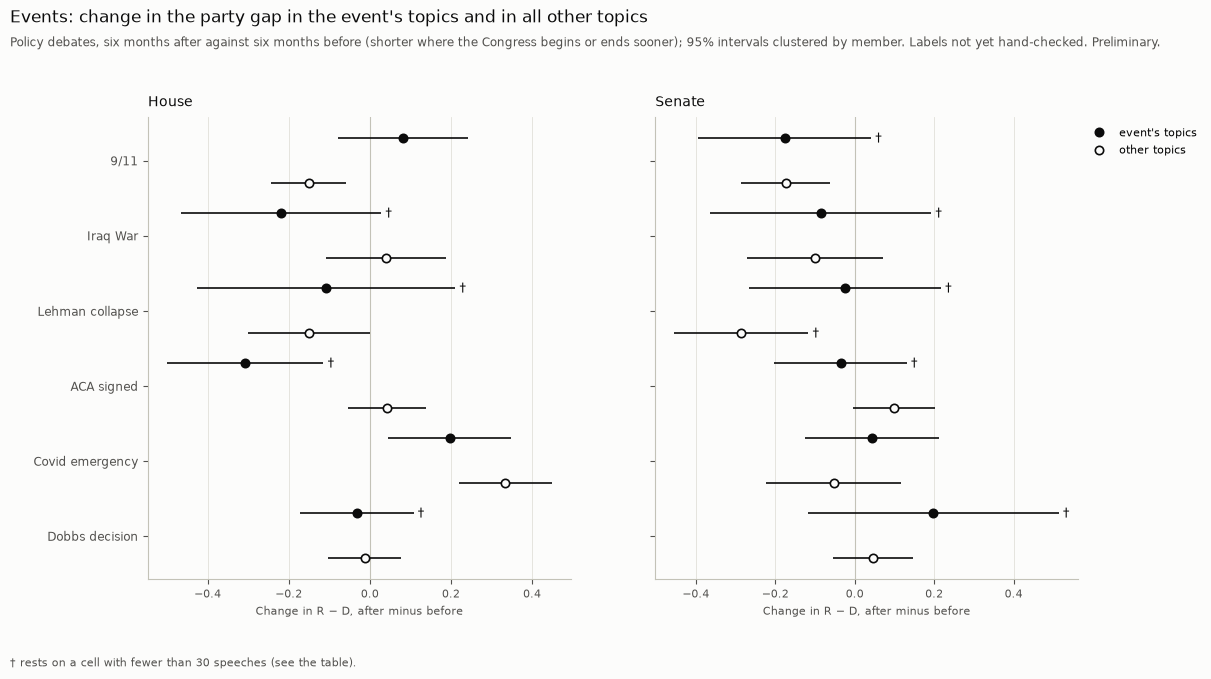

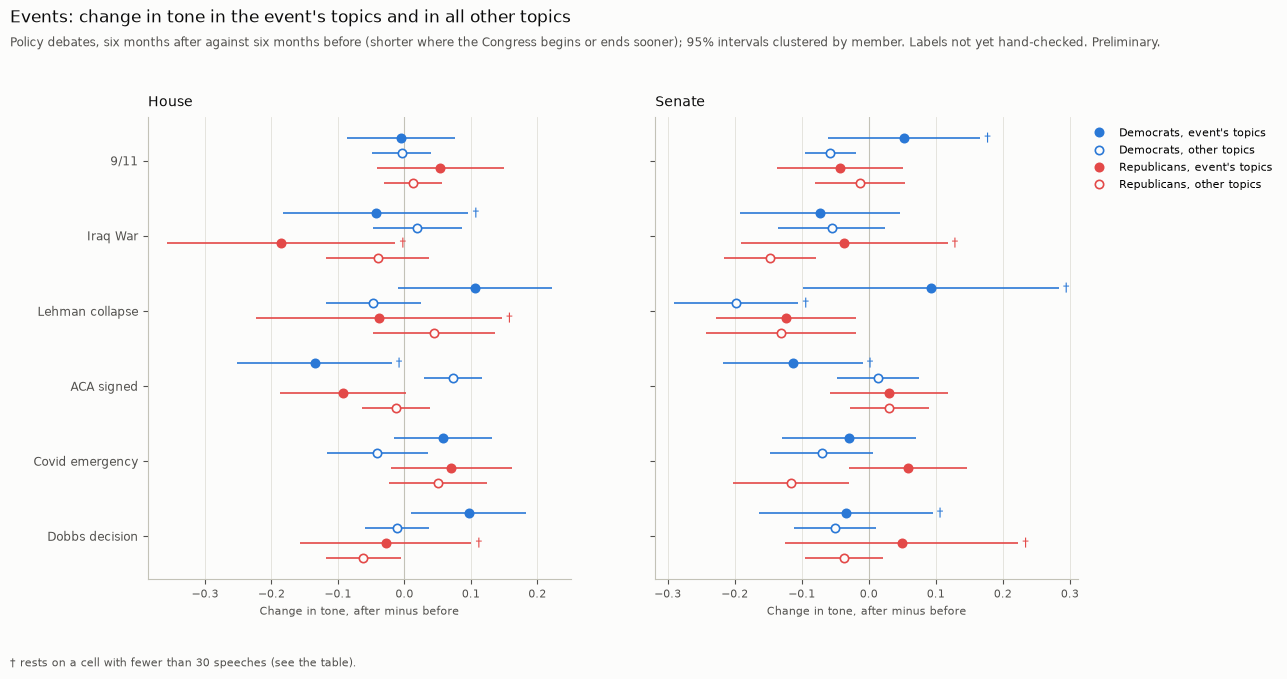

chamber                                                     H  \
group                                                   event   
event           days measure party                              
9/11            182  gap     R−D      +0.081 [-0.080, +0.242]   
                     tone    D        -0.005 [-0.086, +0.077]   
                             R        +0.054 [-0.042, +0.150]   
ACA signed      182  gap     R−D    -0.307 [-0.500, -0.114] †   
                     tone    D      -0.135 [-0.251, -0.019] †   
                             R        -0.092 [-0.188, +0.003]   
Covid emergency 182  gap     R−D      +0.198 [+0.046, +0.349]   
                     tone    D        +0.058 [-0.015, +0.132]   
                             R        +0.070 [-0.021, +0.162]   
Dobbs decision  182  gap     R−D    -0.032 [-0.171, +0.108] †   
                     tone    D        +0.097 [+0.010, +0.183]   
                             R      -0.028 [-0.158, +0.101] †   
Iraq War        76   gap     R−D    -0.219 [-0.466, +0.028] †   
                     tone    D      -0.043 [-0.183, +0.096] †   
                             R      -0.185 [-0.357, -0.014] †   
Lehman collapse 110  gap     R−D    -0.108 [-0.427, +0.211] †   
                     tone    D        +0.106 [-0.009, +0.221]   
                             R      -0.038 [-0.223, +0.147] †   

chamber                                                      \
group                                                 other   
event           days measure party                            
9/11            182  gap     R−D    -0.151 [-0.243, -0.059]   
                     tone    D      -0.004 [-0.048, +0.041]   
                             R      +0.012 [-0.031, +0.056]   
ACA signed      182  gap     R−D    +0.042 [-0.054, +0.138]   
                     tone    D      +0.073 [+0.030, +0.117]   
                             R      -0.013 [-0.064, +0.038]   
Covid emergency 182  gap     R−D    +0.334 [+0.221, +0.448]   
                     tone    D      -0.041 [-0.117, +0.035]   
                             R      +0.050 [-0.024, +0.124]   
Dobbs decision  182  gap     R−D    -0.013 [-0.104, +0.077]   
                     tone    D      -0.011 [-0.059, +0.037]   
                             R      -0.062 [-0.118, -0.006]   
Iraq War        76   gap     R−D    +0.039 [-0.109, +0.187]   
                     tone    D      +0.020 [-0.047, +0.086]   
                             R      -0.040 [-0.117, +0.038]   
Lehman collapse 110  gap     R−D    -0.150 [-0.300, +0.000]   
                     tone    D      -0.047 [-0.119, +0.025]   
                             R      +0.045 [-0.047, +0.136]   

chamber                                                        \
group                                           event − other   
event           days measure party                              
9/11            182  gap     R−D      +0.232 [+0.042, +0.422]   
                     tone    D        -0.001 [-0.090, +0.089]   
                             R        +0.042 [-0.058, +0.141]   
ACA signed      182  gap     R−D    -0.349 [-0.564, -0.134] †   
                     tone    D      -0.208 [-0.324, -0.093] †   
                             R        -0.080 [-0.185, +0.025]   
Covid emergency 182  gap     R−D      -0.137 [-0.322, +0.049]   
                     tone    D        +0.099 [-0.001, +0.199]   
                             R        +0.020 [-0.104, +0.145]   
Dobbs decision  182  gap     R−D    -0.019 [-0.184, +0.146] †   
                     tone    D        +0.108 [+0.009, +0.207]   
                             R      +0.033 [-0.107, +0.174] †   
Iraq War        76   gap     R−D    -0.258 [-0.539, +0.023] †   
                     tone    D      -0.063 [-0.211, +0.086] †   
                             R      -0.145 [-0.327, +0.037] †   
Lehman collapse 110  gap     R−D    +0.041 [-0.298, +0.381] †   
                     tone    D        +0.153 [+0.018, +0.287]   
          

† Estimates resting on a cell under 30 speeches, and the cells:


,event,chamber,measure,party,group,small_cells
9,9/11,S,gap,R−D,event,"D before event: n=24, 16 members"
11,9/11,S,gap,R−D,event − other,"D before event: n=24, 16 members"
12,9/11,S,tone,D,event,"D before event: n=24, 16 members"
14,9/11,S,tone,D,event − other,"D before event: n=24, 16 members"
18,Iraq War,H,gap,R−D,event,"D before event: n=13, 11 members; R before event: n=14, ..."
20,Iraq War,H,gap,R−D,event − other,"D before event: n=13, 11 members; R before event: n=14, ..."
21,Iraq War,H,tone,D,event,"D before event: n=13, 11 members"
23,Iraq War,H,tone,D,event − other,"D before event: n=13, 11 members"
24,Iraq War,H,tone,R,event,"R before event: n=14, 9 members"
26,Iraq War,H,tone,R,event − other,"R before event: n=14, 9 members"


In [5]:
effects = flag_small_event_cells(event_effects(policy, windows), event_sizes)
for measure, label in (("gap", "the party gap"), ("tone", "tone")):
    fig = plot_event_effects(
        effects,
        measure,
        f"Events: change in {label} in the event's topics and in all other topics",
        subtitle="Policy debates, six months after against six months before (shorter where the Congress begins or ends sooner); 95% intervals clustered by member. Labels not yet hand-checked. Preliminary.",
    )
    save_figure(fig, f"deepdive_events_change_{measure}")
    plt.show()
shown = effects.assign(
    estimate_ci=with_ci(effects, "estimate", 3) + np.where(effects["small_cell"], " †", "")
)
display(shown.pivot(index=["event", "days", "measure", "party"], columns=["chamber", "group"],
                    values="estimate_ci"))
print("† Estimates resting on a cell under 30 speeches, and the cells:")
effects.loc[effects["small_cell"], ["event", "chamber", "measure", "party", "group", "small_cells"]]

In [6]:
quarterly = event_quarterly(policy)
counts = quarterly[quarterly["value"] == "ideology"]
full = 2 * 2 * 2 * 4  # chambers x parties x bins before and after
enough = counts[counts["n"] >= TOPIC_MIN_CELL].groupby("event").size().reindex(windows["event"], fill_value=0)
QUARTERLY_EVENTS = [e for e, k in enough.items() if k == full]
print(f"Events with at least {TOPIC_MIN_CELL} speeches per party in every bin: {QUARTERLY_EVENTS or 'none'}")
print("Bins with enough speeches, per event (of", full, "):", enough.to_dict())
for event, k in enough.items():
    if k < full:
        print(f"No quarterly plot for {event}: {full - k} of {full} party x bin cells have "
              f"fewer than {TOPIC_MIN_CELL} speeches (or none).")
for value in ("ideology", "tone"):
    if QUARTERLY_EVENTS:
        fig = plot_event_quarterly(
            quarterly, value, QUARTERLY_EVENTS,
            f"Events by quarter: {value} in the event's topics",
            subtitle="Mean per party in 91-day bins from the event day; bands are 95% intervals clustered by member; dashed: nearest Congress boundary. Labels not yet hand-checked. Preliminary.",
        )
        save_figure(fig, f"deepdive_events_quarterly_{value}")
        plt.show()
tables |= {"event_windows": windows, "event_cell_sizes": event_sizes, "event_effects": effects,
           "event_quarterly": quarterly}

Events with at least 30 speeches per party in every bin: none
Bins with enough speeches, per event (of 32 ): {'9/11': 11, 'Iraq War': 23, 'Lehman collapse': 20, 'ACA signed': 12, 'Covid emergency': 25, 'Dobbs decision': 5}
No quarterly plot for 9/11: 21 of 32 party x bin cells have fewer than 30 speeches (or none).
No quarterly plot for Iraq War: 9 of 32 party x bin cells have fewer than 30 speeches (or none).
No quarterly plot for Lehman collapse: 12 of 32 party x bin cells have fewer than 30 speeches (or none).
No quarterly plot for ACA signed: 20 of 32 party x bin cells have fewer than 30 speeches (or none).
No quarterly plot for Covid emergency: 7 of 32 party x bin cells have fewer than 30 speeches (or none).
No quarterly plot for Dobbs decision: 27 of 32 party x bin cells have fewer than 30 speeches (or none).


**Reading it (A).** Only estimates whose interval excludes zero are read; † marks those
resting on a cell under 30 speeches. **Iraq (±76 days) and Lehman (±110 days, recess and
lame duck after) are the weakest cases:** none of their changes in the event's own topic is
clear.

- **ACA, House:** the gap in health debates fell (−0.31 [−0.50, −0.11] †), by −0.35
  [−0.56, −0.13] † more than in other topics, and Democrats' tone in health fell (−0.14
  [−0.25, −0.02] †). In the Senate the gap change is not clear (−0.04 [−0.20, +0.13] †).
- **9/11:** the gap in all *other* topics fell in both chambers (House −0.15 [−0.24, −0.06],
  Senate −0.17 [−0.29, −0.06]); in defense/foreign it did not (House +0.08 [−0.08, +0.24],
  Senate −0.18 [−0.39, +0.04] †), so in the House the defense gap rose relative to the rest
  (+0.23 [+0.04, +0.42]).
- **Covid, House:** the gap widened in health/economy (+0.20 [+0.05, +0.35]) and in all
  other topics (+0.33 [+0.22, +0.45]); the difference is not clear (−0.14 [−0.32, +0.05]),
  so the widening was general. Senate: no clear change in the gap; Senate Republicans' tone
  fell in other topics (−0.12 [−0.20, −0.03]), so in health/economy it rose relative to the
  rest (+0.18 [+0.04, +0.31]).
- **Dobbs:** House Democrats' tone in social-cultural debates rose (+0.10 [+0.01, +0.18]),
  +0.11 [+0.01, +0.21] beyond other topics; no clear change in the gap in either chamber.
- **Lehman:** the clear changes are in other topics and rest on small cells (Senate gap
  −0.29 [−0.45, −0.12] †, Senate Democrats' tone −0.20 [−0.29, −0.11] †).
- **No quarterly plot:** no event has at least 30 speeches per party in all 32 party × bin
  cells (Covid comes closest with 25 of 32, Dobbs has 5).

## B. Entry cohorts: do new members arrive further out than their party?

**Question.** For each entry cohort since the 107th Congress, how far out does it sit in
its first Congress relative to its own party, chamber and Congress?

**Why.** If each new Republican (or Democratic) cohort arrives further out than the members
already there, polarization renews itself with every election — the replacement story of
notebook 08, seen cohort by cohort.

**How.** Extremity is ideology toward the party's own side (Republicans as scored,
Democrats sign-flipped), taken relative to the mean of the speaker's party, chamber and
Congress over all substantive speeches (as `findings_extremity_by_tenure`, A4). A cohort is
the members whose first Congress in either chamber (`member_background`, Voteview back to
1789) is the 107th or later; only their speeches in that first Congress count. Members who
served earlier under another ICPSR (party switchers, whom Voteview renumbers;
`prior_service_switchers`) are left out. Means per chamber, party and cohort, clustered by
member, with speeches and members. **Limits:** Senate cohorts are small (n shown, nothing
pooled); a senator who served in the House first is not a Senate newcomer here; a member
with few speeches in their first Congress is seen through those few.

ICPSRs left out as earlier service under another ICPSR (17 with speeches):


,bioguide_id,icpsr,bioname,first_congress,person_first_congress
4,T000254,9369,"THURMOND, James Strom",89,84
11,G000365,14628,"GRAMM, William Philip (Phil)",98,96
12,S001044,14454,"STUMP, Robert Lee",98,95
17,C000077,95407,"CAMPBELL, Ben Nighthorse",104,100
18,D000168,99342,"DEAL, John Nathan",104,103
22,S000320,94659,"SHELBY, Richard C.",104,96
23,T000058,94679,"TAUZIN, Wilbert Joseph (Billy)",104,96
24,W000194,29749,"WATKINS, Wesley Wade",105,95
28,G000280,89767,"GOODE, Virgil H., Jr.",107,105
29,J000072,94240,"JEFFORDS, James Merrill",107,94


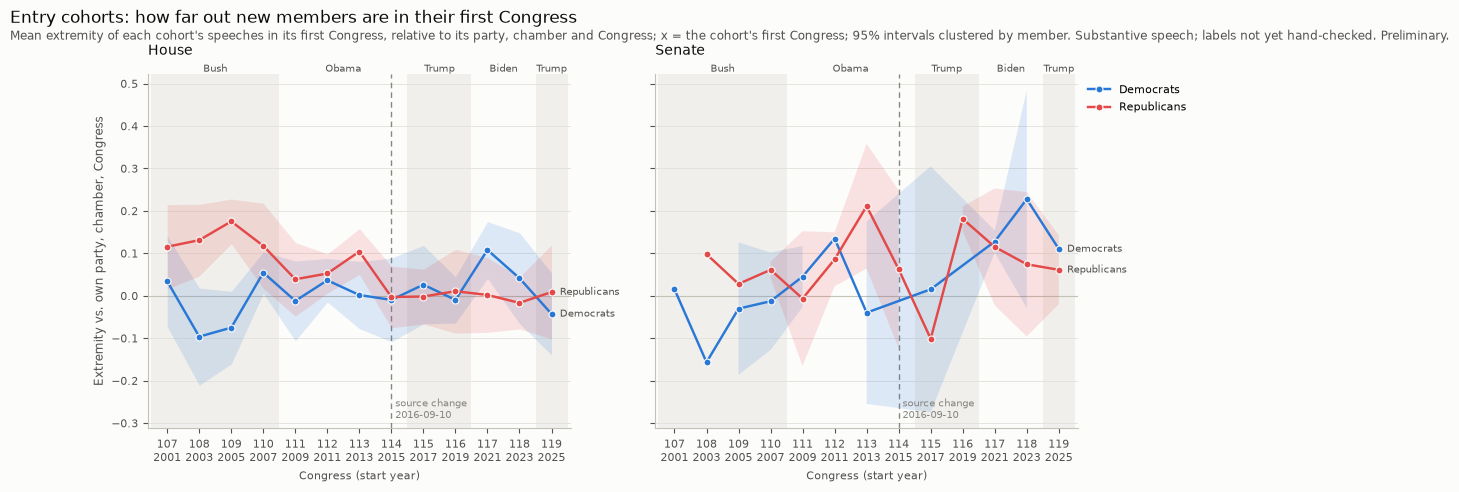

mean_ci                           \
chamber                        H                            
party                          D                        R   
cohort                                                      
107      +0.034 [-0.073, +0.141]  +0.116 [+0.016, +0.215]   
108      -0.096 [-0.211, +0.018]  +0.131 [+0.047, +0.215]   
109      -0.075 [-0.161, +0.010]  +0.175 [+0.123, +0.228]   
110      +0.055 [+0.006, +0.103]  +0.118 [+0.017, +0.218]   
111      -0.012 [-0.106, +0.082]  +0.039 [-0.048, +0.125]   
112      +0.036 [-0.015, +0.088]  +0.052 [+0.006, +0.099]   
113      +0.002 [-0.077, +0.081]  +0.104 [+0.050, +0.158]   
114      -0.010 [-0.108, +0.089]  -0.003 [-0.075, +0.070]   
115      +0.026 [-0.066, +0.119]  -0.002 [-0.066, +0.063]   
116      -0.010 [-0.064, +0.045]  +0.011 [-0.088, +0.109]   
117      +0.108 [+0.041, +0.175]  +0.002 [-0.086, +0.090]   
118      +0.041 [-0.065, +0.148]  -0.017 [-0.078, +0.045]   
119      -0.043 [-0.139, +0.054]  +0.009 [-0.102, +0.119]   

                                                             n                 \
chamber                        S                             H         S        
party                          D                        R    D    R    D    R   
cohort                                                                          
107      +0.015 [-0.120, +0.151]                      NaN   80  133   66  NaN   
108          -0.157 [+nan, +nan]  +0.098 [-0.091, +0.287]  111  182    4   69   
109      -0.030 [-0.186, +0.126]      +0.028 [+nan, +nan]  130  180   45    6   
110      -0.013 [-0.128, +0.102]  +0.061 [+0.042, +0.080]  285   84   71   17   
111      +0.045 [-0.027, +0.117]  -0.007 [-0.165, +0.152]  260  162  110   68   
112          +0.135 [+nan, +nan]  +0.086 [+0.022, +0.149]   66  407   13  119   
113      -0.040 [-0.255, +0.175]  +0.211 [+0.064, +0.358]  247  208   56   62   
114                          NaN  +0.062 [-0.124, +0.248]   89  213  NaN   42   
115      +0.015 [-0.275, +0.305]      -0.101 [+nan, +nan]  163  186   21    8   
116                          NaN  +0.181 [+0.152, +0.210]  297  156  NaN   64   
117      +0.128 [+0.102, +0.154]  +0.115 [-0.023, +0.253]  137  256   46   49   
118      +0.228 [-0.029, +0.484]  +0.074 [-0.096, +0.244]  192  293    9   66   
119          +0.110 [+nan, +nan]  +0.061 [-0.020, +0.142]  232  158    7   36   

        n_members                
chamber         H        S       
party           D   R    D    R  
cohort                           
107            13  30    5  NaN  
108            14  31    1    5  
109            16  21    2    1  
110            41  16    6    2  
111            34  25   10    4  
112            12  79    1    5  
113            40  35    7    3  
114            16  42  NaN    6  
115            25  33    5    1  
116            54  31  NaN    5  
117            20  47    3    2  
118            34  39    2    4  
119            31  29    1    6

In [7]:
members = add_background(df, member_background())
members["extremity_vs_cell"] = relative_to_cell(members, "extremity")
switchers = prior_service_switchers()
in_data = switchers[switchers["icpsr"].isin(members["icpsr"].dropna().astype(int))]
print(f"ICPSRs left out as earlier service under another ICPSR ({len(in_data)} with speeches):")
display(in_data)
cohorts = cohort_extremity(members, exclude_icpsr=in_data["icpsr"].tolist())
fig = plot_party_positions(
    cohorts.rename(columns={"cohort": "congress_number"}),
    "Extremity vs. own party, chamber, Congress",
    "Entry cohorts: how far out new members are in their first Congress",
    subtitle="Mean extremity of each cohort's speeches in its first Congress, relative to its party, chamber and Congress; x = the cohort's first Congress; 95% intervals clustered by member. Substantive speech; labels not yet hand-checked. Preliminary.",
)
save_figure(fig, "deepdive_cohorts")
plt.show()
cohorts.assign(mean_ci=with_ci(cohorts, digits=3)).pivot(
    index="cohort", columns=["chamber", "party"], values=["mean_ci", "n", "n_members"]
)

In [8]:
tables["cohort_extremity"] = cohorts
tables["cohort_switchers_left_out"] = in_data

**Reading it (B).**

- **House Republicans:** the cohorts of the 107th–110th, 112th and 113th Congress sit further
  out than their party in their first Congress (+0.05 to +0.18; e.g. 109th +0.18 [+0.12,
  +0.23], 113th +0.10 [+0.05, +0.16]). The cohorts from the 114th on sit at their party's
  mean (−0.02 to +0.01, every interval across zero).
- **House Democrats:** mostly at their party's mean; further out in the 110th (+0.06
  [+0.01, +0.10]) and the 117th (+0.11 [+0.04, +0.18]).
- **Senate:** cohorts hold 1–10 members (table); several have a single member and no
  interval. Not read cohort by cohort.
- 17 ICPSRs with earlier service under another number are left out (among them Specter,
  Jeffords, Manchin and Sinema).

## 9. Dissenters: are there still members between the parties?

**Question.** How widely are each party's members spread, how many sit closer to the other
party than to their own, and are those moderates more likely to leave?

**Why.** Members between the parties are the people who make bipartisan majorities
possible; if they vanish, or leave faster than others, the bridges between the parties go
with them.

**How.** A unit is a member in one Congress with at least 10 substantive speeches
(`member_trajectories`, A3/A5's threshold), scored by the mean of those speeches. Per party,
chamber and Congress: the SD of the member means, and the share of **moderates** — members
whose mean lies closer to the other party's median member than to their own party's median
(decided 2026-11-02, A8). Robustness: the share with |mean| < 0.2. Intervals from a
bootstrap over members within party, chamber and Congress, the medians redrawn with them
(1,000 draws). Exit: whether the member sits in the same chamber in the next Congress
(Voteview service, not sample presence), moderates against all others; the last Congress is
left out (unknown who leaves). Raw shares, and a linear probability model of leaving on
being moderate within Congress, per chamber and party, clustered by member.
**Limits:** in the House the units are the most frequent 15–30% of speakers (A5); the SD of
member means includes noise that falls with more speeches; leaving mixes retirement,
defeat and a move to the other chamber.

2,210 member x Congress units with >= 10 substantive speeches


dissent bootstrap: 2.8 min


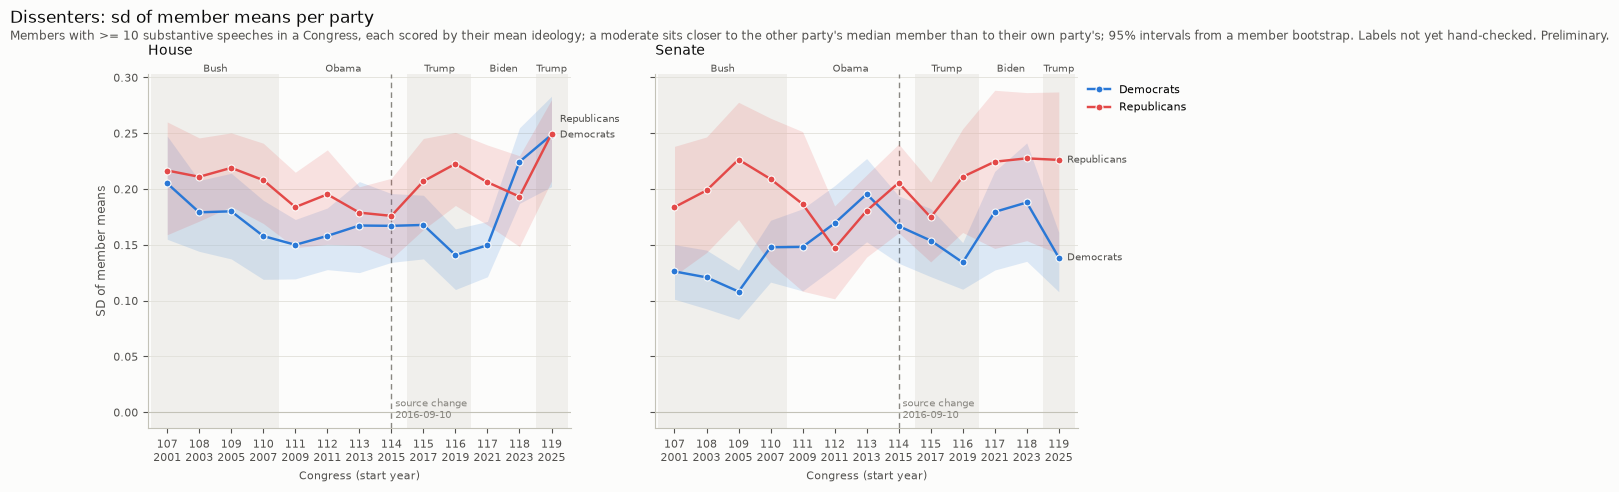

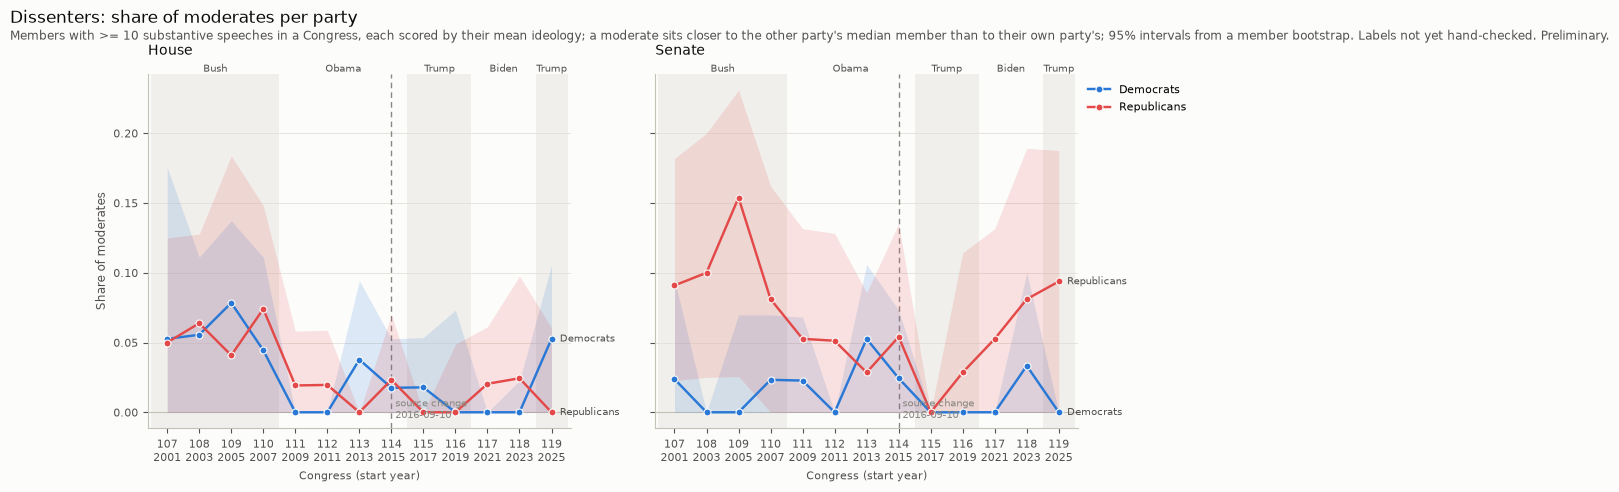

chamber                                H                           \
party                                  D                        R   
statistic                             sd                       sd   
congress_number                                                     
107              +0.205 [+0.155, +0.247]  +0.217 [+0.159, +0.260]   
108              +0.179 [+0.144, +0.208]  +0.211 [+0.171, +0.246]   
109              +0.180 [+0.137, +0.214]  +0.219 [+0.184, +0.250]   
110              +0.158 [+0.119, +0.190]  +0.208 [+0.169, +0.241]   
111              +0.150 [+0.120, +0.173]  +0.184 [+0.147, +0.215]   
112              +0.158 [+0.128, +0.183]  +0.195 [+0.151, +0.235]   
113              +0.167 [+0.125, +0.207]  +0.179 [+0.150, +0.202]   
114              +0.167 [+0.134, +0.196]  +0.176 [+0.138, +0.210]   
115              +0.168 [+0.137, +0.194]  +0.207 [+0.164, +0.245]   
116              +0.141 [+0.110, +0.164]  +0.223 [+0.185, +0.251]   
117              +0.150 [+0.121, +0.171]  +0.206 [+0.168, +0.239]   
118              +0.224 [+0.187, +0.255]  +0.193 [+0.149, +0.230]   
119              +0.249 [+0.202, +0.283]  +0.249 [+0.207, +0.280]   

chamber                                S                           \
party                                  D                        R   
statistic                             sd                       sd   
congress_number                                                     
107              +0.126 [+0.101, +0.150]  +0.184 [+0.122, +0.238]   
108              +0.121 [+0.093, +0.145]  +0.199 [+0.143, +0.247]   
109              +0.108 [+0.083, +0.127]  +0.226 [+0.173, +0.278]   
110              +0.148 [+0.117, +0.172]  +0.209 [+0.133, +0.263]   
111              +0.148 [+0.109, +0.182]  +0.187 [+0.109, +0.251]   
112              +0.169 [+0.130, +0.203]  +0.147 [+0.102, +0.185]   
113              +0.196 [+0.153, +0.227]  +0.181 [+0.139, +0.213]   
114              +0.167 [+0.134, +0.194]  +0.206 [+0.161, +0.240]   
115              +0.154 [+0.122, +0.183]  +0.175 [+0.135, +0.206]   
116              +0.134 [+0.110, +0.152]  +0.211 [+0.161, +0.254]   
117              +0.180 [+0.127, +0.216]  +0.225 [+0.147, +0.289]   
118              +0.188 [+0.135, +0.241]  +0.228 [+0.154, +0.286]   
119              +0.139 [+0.108, +0.161]  +0.226 [+0.142, +0.287]   

chamber                                H                           \
party                                  D                        R   
statistic                 share_moderate           share_moderate   
congress_number                                                     
107              +0.053 [+0.000, +0.175]  +0.050 [+0.000, +0.125]   
108              +0.056 [+0.000, +0.111]  +0.064 [+0.000, +0.128]   
109              +0.078 [+0.000, +0.137]  +0.041 [+0.000, +0.184]   
110              +0.044 [+0.000, +0.111]  +0.074 [+0.000, +0.148]   
111              +0.000 [+0.000, +0.000]  +0.019 [+0.000, +0.058]   
112              +0.000 [+0.000, +0.000]  +0.020 [+0.000, +0.059]   
113              +0.038 [+0.000, +0.094]  +0.000 [+0.000, +0.000]   
114              +0.018 [+0.000, +0.053]  +0.023 [+0.000, +0.070]   
115              +0.018 [+0.000, +0.054]  +0.000 [+0.000, +0.000]   
116              +0.000 [+0.000, +0.073]  +0.000 [+0.000, +0.049]   
117              +0.000 [+0.000, +0.000]  +0.020 [+0.000, +0.061]   
118              +0.000 [+0.000, +0.023]  +0.024 [+0.000, +0.098]   
119              +0.053 [+0.000, +0.105]  +0.000 [+0.000, +0.061]   

chamber                                S                           \
party                                  D                        R   
statistic                 share_moderate           share_moderate   
congress_number                                                     
107              +0.024 [+0.000, +0.095]  +0.091 [+0.023, +0.182]   
108              +0.000 [+0.000, +0.000]  +0.100 [+0.025, +0.200]   
109              +0.000 [+0.000, +0.070]  +0.154 [+0.026, +0.231

In [9]:
units = member_trajectories(df, "ideology", MEMBER_MIN_SPEECHES)
print(f"{len(units):,} member x Congress units with >= {MEMBER_MIN_SPEECHES} substantive speeches")
dissent = timed("dissent bootstrap", dissent_table, units, n_draws=DEEP_DIVE_BOOTSTRAP)
for statistic, label, file in (
    ("sd", "SD of member means", "deepdive_dissent_sd"),
    ("share_moderate", "Share of moderates", "deepdive_dissent_moderates"),
):
    part = dissent[dissent["statistic"] == statistic].rename(columns={"value": "mean"})
    fig = plot_party_positions(
        part,
        label,
        f"Dissenters: {label.lower()} per party",
        subtitle="Members with >= 10 substantive speeches in a Congress, each scored by their mean ideology; a moderate sits closer to the other party's median member than to their own party's; 95% intervals from a member bootstrap. Labels not yet hand-checked. Preliminary.",
    )
    save_figure(fig, file)
    plt.show()
dissent.assign(value_ci=with_ci(dissent, "value", 3)).pivot(
    index="congress_number", columns=["chamber", "party", "statistic"], values="value_ci"
)

In [10]:
exits = moderate_exit(units, chamber_membership(), LAST_CONGRESS)
exit_raw = pd.concat(
    [cell_means(exits, "left", by=("chamber", "party", flag)).rename(columns={flag: "flag_value"}).assign(flag=flag)
     for flag in ("moderate", "centrist")],
    ignore_index=True,
)
exit_lpm = pd.concat(
    [within_cell_ols(exits, "left", [flag], cell=("congress_number",), by=("chamber", "party"))
     for flag in ("moderate", "centrist")],
    ignore_index=True,
)
print("Share leaving the chamber after the Congress, by flag (95% interval, clustered by member):")
display(exit_raw.assign(share=pct_ci(exit_raw))[["flag", "chamber", "party", "flag_value", "share", "n", "n_members"]])
print("Difference in the chance of leaving, within Congress (linear probability model):")
exit_lpm.assign(coef_ci=with_ci(exit_lpm, "coef", 3))[["term", "chamber", "party", "coef_ci", "p", "n", "n_members"]]

Share leaving the chamber after the Congress, by flag (95% interval, clustered by member):


,flag,chamber,party,flag_value,share,n,n_members
0,moderate,H,D,0,"8.8% [6.6, 11.1]",577,202
1,moderate,H,D,1,"18.8% [-0.8, 38.3]",16,12
2,moderate,H,R,0,"12.1% [9.6, 14.6]",538,231
3,moderate,H,R,1,"31.2% [8.5, 54.0]",16,14
4,moderate,S,D,0,"8.6% [6.3, 10.9]",465,91
5,moderate,S,D,1,"28.6% [-7.6, 64.7]",7,7
6,moderate,S,R,0,"10.6% [7.8, 13.4]",424,108
7,moderate,S,R,1,"10.0% [-0.8, 20.8]",30,10
8,centrist,H,D,0,"7.7% [5.6, 9.9]",517,181
9,centrist,H,D,1,"18.4% [10.0, 26.8]",76,58


Difference in the chance of leaving, within Congress (linear probability model):


,term,chamber,party,coef_ci,p,n,n_members
0,moderate,H,D,"+0.134 [-0.047, +0.315]",0.146,593,208
1,moderate,H,R,"+0.218 [-0.001, +0.437]",0.052,554,239
2,moderate,S,D,"+0.171 [-0.149, +0.491]",0.295,472,95
3,moderate,S,R,"-0.009 [-0.109, +0.090]",0.857,454,110
4,centrist,H,D,"+0.121 [+0.037, +0.206]",0.005,593,208
5,centrist,H,R,"+0.057 [-0.018, +0.132]",0.139,554,239
6,centrist,S,D,"-0.003 [-0.066, +0.059]",0.923,472,95
7,centrist,S,R,"+0.084 [-0.007, +0.175]",0.071,454,110


In [11]:
tables |= {"dissent": dissent, "moderate_exit": exit_raw, "moderate_exit_lpm": exit_lpm}

**Reading it (9).** 2,210 member × Congress units with at least 10 substantive speeches.

- **Spread:** House Democrats' SD fell from 0.21 [0.16, 0.25] (107th) to 0.14 [0.11, 0.16]
  (116th) and rose to 0.25 [0.20, 0.28] in the 119th; House Republicans 0.18–0.22
  throughout, 0.25 [0.21, 0.28] in the 119th. Senate Democrats 0.11–0.20 and Senate
  Republicans 0.15–0.23, with no steady direction.
- **Moderates** (closer to the other party's median member) are rare throughout: in the
  House 0–8% per party and Congress, and 0% in several Congresses after the 110th; Senate
  Republicans 9–15% in the 107th–109th, 0–9% after. The intervals reach zero almost
  everywhere.
- **The robustness share (|mean| < 0.2) falls more clearly:** House Republicans 38% [23, 53]
  in the 107th, 8–12% in the 117th–119th (the 116th, 37%, is an exception); Senate
  Republicans 36–43% in the 107th–109th, 5–26% later; Senate Democrats 36% in the 107th,
  0–15% in the 115th–119th.
- **Leaving:** moderates left the House more often (Democrats 18.8% against 8.8%,
  Republicans 31.2% against 12.1%), but these rest on 16 units each; within Congress the
  differences are +0.13 [−0.05, +0.32] and +0.22 [−0.00, +0.44]. With the robustness
  definition, House Democrats near the centre leave more often (+0.12 [+0.04, +0.21]); the
  other three groups are not clear.

## 4. The last Congress: do members speak more mildly before they leave?

**Question.** Is a member's extremity or tone different in their last Congress than in
their earlier ones?

**Why.** If members soften once re-election no longer matters, the pressure of the next
election — primaries in particular — is part of what keeps them apart.

**How.** Notebook 08's model C — member fixed effects, the Congress number as a trend,
out of the White House (`opposition`) and the chamber minority — plus `last_congress`: 1 in
the member's last Congress before they sit in neither chamber (Voteview, by bioguide id, so
a party switcher's new ICPSR is not leaving; a move from House to Senate is not leaving).
The data's last Congress is left out, since who leaves after it is not known yet. For
extremity and tone, per chamber and party, clustered by member, with the number of members
whose `last_congress` changes while they speak (only they identify it).
**Limits:** the data do not say whether a member retired, lost or died; a member who knows
they will retire may already change before their last Congress.

65,850 speeches with a known last-Congress status (Congress < 119); 6,701 in a member's last Congress


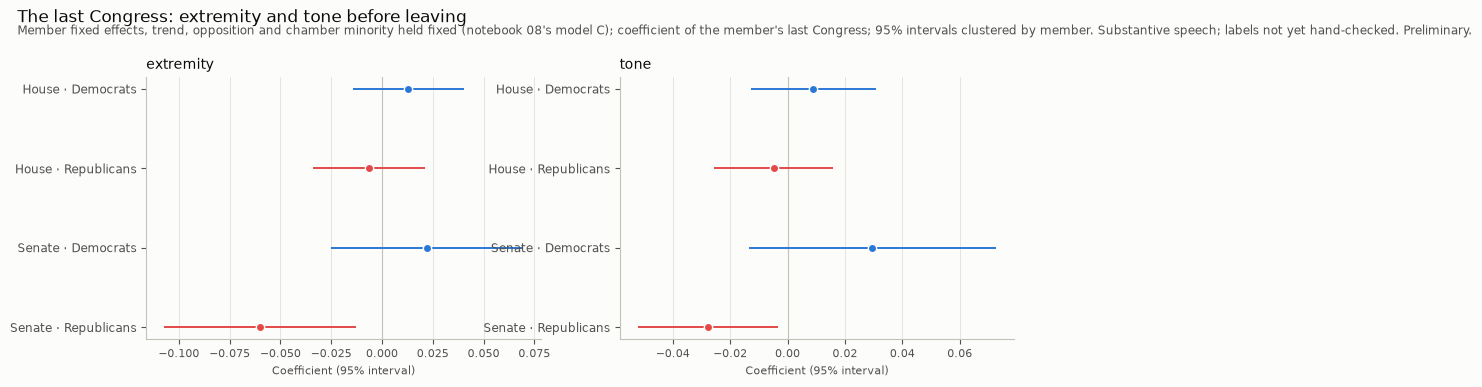

,chamber,party,term,n_members,n_identifying,n_speeches_identifying
0,H,D,last_congress,542,208,8959
1,H,R,last_congress,654,309,10325
2,S,D,last_congress,117,58,8067
3,S,R,last_congress,124,66,7583


,value,chamber,party,coef_ci,p,n,n_members
3,extremity,H,D,"+0.013 [-0.014, +0.040]",0.351,18527,542
7,extremity,H,R,"-0.007 [-0.034, +0.021]",0.640,17029,654
11,extremity,S,D,"+0.022 [-0.025, +0.069]",0.355,15232,117
15,extremity,S,R,"-0.060 [-0.107, -0.013]",0.013,15062,124
19,tone,H,D,"+0.009 [-0.013, +0.031]",0.415,18527,542
23,tone,H,R,"-0.005 [-0.026, +0.016]",0.647,17029,654
27,tone,S,D,"+0.030 [-0.014, +0.073]",0.179,15232,117
31,tone,S,R,"-0.028 [-0.052, -0.003]",0.025,15062,124


In [12]:
service = person_service()
last = add_last_congress(df, service, LAST_CONGRESS)
last = last.dropna(subset=["last_congress"])
print(f"{len(last):,} speeches with a known last-Congress status (Congress < {LAST_CONGRESS}); "
      f"{int(last['last_congress'].sum()):,} in a member's last Congress")
last_fits = last_congress_models(last)
last_identifying = identifying_members(last, terms=("last_congress",))
fig = plot_term_coefficients(
    last_fits, "last_congress",
    "The last Congress: extremity and tone before leaving",
    subtitle="Member fixed effects, trend, opposition and chamber minority held fixed (notebook 08's model C); coefficient of the member's last Congress; 95% intervals clustered by member. Substantive speech; labels not yet hand-checked. Preliminary.",
)
save_figure(fig, "deepdive_last_congress")
plt.show()
display(last_identifying)
shown = last_fits[last_fits["term"] == "last_congress"]
shown.assign(coef_ci=with_ci(shown, "coef", 3))[["value", "chamber", "party", "coef_ci", "p", "n", "n_members"]]

In [13]:
tables |= {"last_congress": last_fits, "last_congress_identifying": last_identifying}

**Reading it (4).** 65,850 speeches with a known status (Congresses before the 119th), 6,701
of them in a member's last Congress; 58–309 members per group identify the effect.

- **Senate Republicans** speak less extremely (−0.060 [−0.107, −0.013]) and more mildly
  (tone −0.028 [−0.052, −0.003]) in their last Congress than in their earlier ones, with
  member fixed effects, trend, opposition and chamber minority held fixed.
- **No clear effect in the other three groups** (extremity −0.007 to +0.022, tone −0.005 to
  +0.030, every interval across zero).

## Keyword lists: how they were checked

Three analyses (2 + 7, 6, 3) count words. The lists were fixed before any result was seen
(`deep_dive.KEYWORD_LISTS`, `OTHER_PARTY_TERMS`, `KEYWORD_EXCLUDE`; A8): whole words or
phrases, case ignored, inflections written out, and uses that are not what a list measures
taken out first (e.g. "trade deficit", "Soviet Socialist"). Each list was checked by hand
on 50 random hits from the substantive `d100k` speeches (seed 42, one hit per speech;
`results/metrics/deepdive_keyword_check_<list>.csv`, the definition of a true hit in each
file's first line). Two first lists failed and were changed before any analysis was run:
`presidential_power` (dropped) and the first `hostility` list (replaced by targeted
phrases, checked again as `hostility_v2`).

**Main basis:** the substantive `d100k` speeches (A3, decided 2026-11-02). **Robustness:**
the whole corpus (580,007 speeches, all speech types, no labels), read in batches. Each
table carries hits per 10,000 words beside the share of speeches, because govinfo text is
cut to the member's own words (D17), so speech length — and with it the chance of a hit —
changes at the source break. Text ends with the corpus on 2025-12-19 (D15).

In [14]:
CHECKED = ["cooperation", "deficit", "other_party", "undo", "hostility", "presidential_power", "hostility_v2"]
precision = keyword_precision(
    {name: read_keyword_check(METRICS_DIR / f"deepdive_keyword_check_{name}.csv") for name in CHECKED}
)
precision["status"] = precision["list"].map(
    {"hostility": "failed, replaced by hostility_v2", "presidential_power": "failed, dropped"}
).fillna("used")
display(precision)

texts = speech_texts(df["speech_id"].tolist())
df_text = df.assign(text=df["speech_id"].map(texts))
assert df_text["text"].notna().all(), "a scored speech has no text in the corpus"
hits = keyword_hits(df_text)
del df_text, texts
LISTS = [*KEYWORD_LISTS, "other_party"]
YEAR = pd.to_datetime(df["date"]).dt.year
counts = keyword_counts_by_year(hits, YEAR, LISTS)
print("Substantive d100k speeches with a hit, per list and year:")
display(counts)
empty = counts[LISTS].eq(0).sum()
print("Years with no hit, per list:", empty.to_dict())
assert (empty == 0).all(), "a list has a year with no hit: explain before reading it"

,list,n_checked,n_correct,precision,status
0,cooperation,50,43,0.86,used
1,deficit,50,49,0.98,used
2,other_party,50,49,0.98,used
3,undo,50,48,0.96,used
4,hostility,50,28,0.56,"failed, replaced by hostility_v2"
5,presidential_power,50,18,0.36,"failed, dropped"
6,hostility_v2,50,40,0.80,used


Substantive d100k speeches with a hit, per list and year:


,year,cooperation,hostility,deficit,undo,other_party
0,2001,691,10,129,121,280
1,2002,475,12,133,110,314
2,2003,629,23,246,143,531
3,2004,477,6,224,79,344
4,2005,648,12,245,107,461
5,2006,543,8,195,85,410
6,2007,811,6,202,115,562
7,2008,571,16,114,63,417
8,2009,581,38,367,83,499
9,2010,627,27,436,164,592


Years with no hit, per list: {'cooperation': 0, 'hostility': 0, 'deficit': 0, 'undo': 0, 'other_party': 0}


In [15]:
start = time.time()
corpus = load_corpus_keyword_hits()
timings["corpus keyword pass"] = time.time() - start
CORPUS_YEAR = pd.to_datetime(corpus["date"]).dt.year
HIT_COLUMNS = [c for name in LISTS for c in (name, f"{name}_hits")]
corpus_flags, corpus = corpus[HIT_COLUMNS], corpus.drop(columns=HIT_COLUMNS)
corpus_counts = keyword_counts_by_year(corpus_flags, CORPUS_YEAR, LISTS)
print(f"Corpus: {len(corpus):,} speeches, read in {timings['corpus keyword pass'] / 60:.1f} min; with a hit per year:")
display(corpus_counts)
assert (corpus_counts[LISTS].eq(0).sum() == 0).all(), "a list has a corpus year with no hit"
tables |= {"keyword_precision": precision, "keyword_counts": counts.assign(basis="d100k substantive"),
           "keyword_counts_corpus": corpus_counts.assign(basis="corpus")}

Corpus: 580,007 speeches, read in 10.2 min; with a hit per year:


,year,cooperation,hostility,deficit,undo,other_party
0,2001,5706,93,1132,954,2670
1,2002,4458,70,1277,789,2869
2,2003,5642,132,2125,1150,4736
3,2004,4800,87,1861,743,3334
4,2005,5759,139,2105,931,4082
5,2006,4851,72,1642,738,3761
6,2007,8130,100,1870,938,5740
7,2008,5475,124,961,650,3864
8,2009,3997,234,2194,456,3386
9,2010,4628,165,2641,1005,4118


## 2 + 7. Power and words: deficits and undoing

**Question.** Does a party talk more about deficits, and about repealing and overturning,
when it is out of the White House than when it holds it?

**Why.** If deficit worries and the urge to undo the other side's work rise and fall with
power rather than with the budget or the laws themselves, positions follow the struggle for
power — the opposition is against because it is the opposition, and each president undoes
the last.

**How.** Two lists that passed the hand check: `deficit` (98% true hits) and `undo` (96%);
the third planned list, presidential power, failed (36%) and is dropped. The share of
speeches with at least one hit, per party and chamber, with the party in the White House
and in opposition (raw), and the opposition effect **net of the trend**: notebook 07's model
A (A6) on the 0/1 hit, OLS on the Congress number and `opposition` per chamber and party,
clustered by member. A yearly view shades the presidencies. Robustness: the same on the
whole corpus. **Limits:** four changes of the White House; a word count says nothing about
which side of the issue a speaker takes; hits per 10,000 words shown beside the shares.

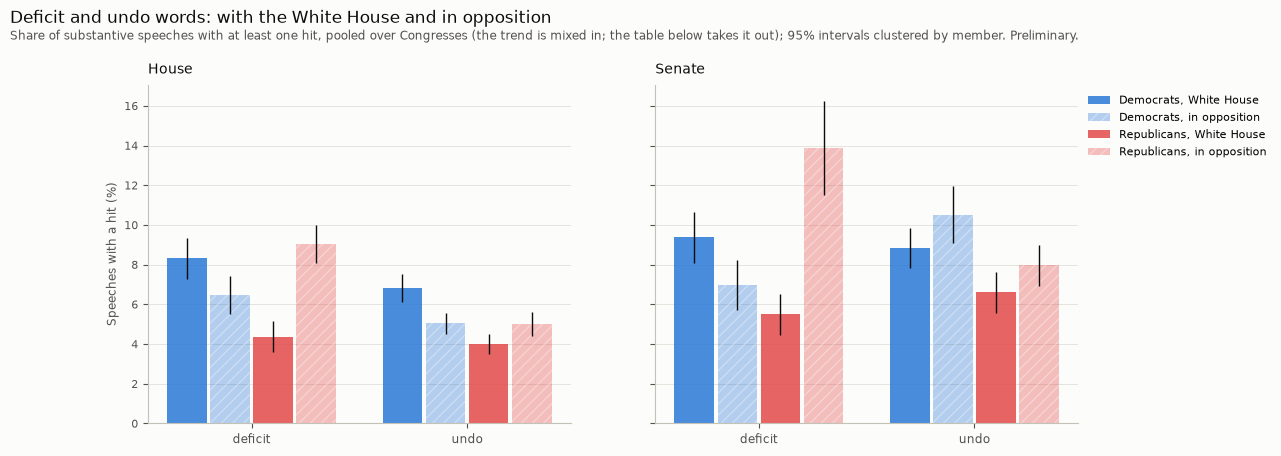

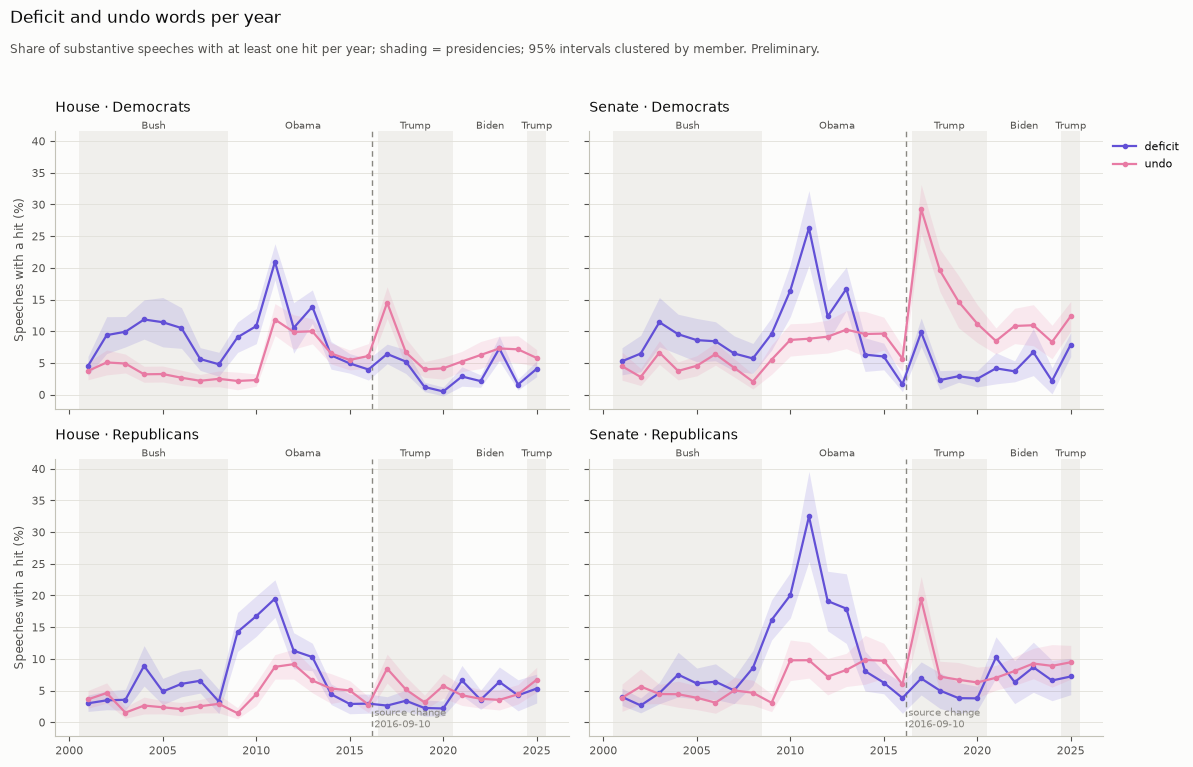

Opposition effect net of the trend (difference in the share of speeches with a hit):


,list,chamber,party,coef_ci,p,n,n_members
1,deficit,H,D,"-0.035 [-0.047, -0.024]",1.269e-09,19929,580
3,deficit,H,R,"+0.057 [+0.046, +0.068]",1.318e-23,18313,695
5,deficit,S,D,"-0.033 [-0.047, -0.018]",8.982e-06,16792,123
7,deficit,S,R,"+0.095 [+0.068, +0.122]",3.733e-12,16087,132
9,undo,H,D,"-0.012 [-0.020, -0.004]",2.435e-03,19929,580
11,undo,H,R,"+0.005 [-0.003, +0.014]",1.909e-01,18313,695
13,undo,S,D,"+0.034 [+0.022, +0.047]",1.551e-07,16792,123
15,undo,S,R,"+0.003 [-0.008, +0.013]",6.165e-01,16087,132


In [16]:
POWER = ["deficit", "undo"]
power = keyword_shares(df, hits, POWER, by=("chamber", "party", "in_opposition"))
power_effect = keyword_opposition_effects(df, hits, POWER)
power_yearly = keyword_shares(df.assign(year=YEAR), hits, POWER, by=("year", "chamber", "party"))
fig = plot_keyword_by_opposition(
    power, POWER,
    "Deficit and undo words: with the White House and in opposition",
    subtitle="Share of substantive speeches with at least one hit, pooled over Congresses (the trend is mixed in; the table below takes it out); 95% intervals clustered by member. Preliminary.",
)
save_figure(fig, "deepdive_power_words_opposition")
plt.show()
fig = plot_yearly_keyword_lines(
    power_yearly, POWER,
    "Deficit and undo words per year",
    subtitle="Share of substantive speeches with at least one hit per year; shading = presidencies; 95% intervals clustered by member. Preliminary.",
    incomplete=INCOMPLETE_YEAR,
)
save_figure(fig, "deepdive_power_words_yearly")
plt.show()
shown = power_effect[power_effect["term"] == "opposition"]
print("Opposition effect net of the trend (difference in the share of speeches with a hit):")
shown.assign(coef_ci=with_ci(shown, "coef", 3))[["list", "chamber", "party", "coef_ci", "p", "n", "n_members"]]

In [17]:
power.assign(share=pct_ci(power)).pivot(
    index=["list", "chamber", "party"], columns="in_opposition", values=["share", "per_10k_words"]
)

share                     per_10k_words  \
in_opposition                     False               True          False   
list    chamber party                                                       
deficit H       D       8.3% [7.3, 9.3]     6.5% [5.5, 7.4]         5.317   
                R       4.4% [3.6, 5.1]    9.0% [8.1, 10.0]         2.189   
        S       D      9.4% [8.1, 10.6]     7.0% [5.7, 8.2]         4.122   
                R       5.5% [4.5, 6.5]  13.9% [11.5, 16.3]         1.914   
undo    H       D       6.8% [6.1, 7.5]     5.1% [4.5, 5.6]         3.071   
                R       4.0% [3.5, 4.5]     5.0% [4.4, 5.6]         1.422   
        S       D       8.8% [7.8, 9.9]   10.5% [9.1, 11.9]         2.007   
                R       6.6% [5.6, 7.6]     8.0% [6.9, 9.0]         1.607   

                              
in_opposition          True   
list    chamber party         
deficit H       D      4.415  
                R      5.648  
        S       D      2.753  
                R      5.562  
undo    H       D      2.028  
                R        2.0  
        S       D      2.595  
                R      1.663

In [18]:
power_corpus = keyword_shares(corpus, corpus_flags, POWER, by=("chamber", "party", "in_opposition"))
power_effect_corpus = keyword_opposition_effects(corpus, corpus_flags, POWER)
shown = power_effect_corpus[power_effect_corpus["term"] == "opposition"]
print("Robustness, whole corpus: opposition effect net of the trend")
display(shown.assign(coef_ci=with_ci(shown, "coef", 3))[["list", "chamber", "party", "coef_ci", "p", "n"]])
tables |= {"power_words": power, "power_words_effect": power_effect, "power_words_yearly": power_yearly,
           "power_words_corpus": power_corpus, "power_words_effect_corpus": power_effect_corpus}

Robustness, whole corpus: opposition effect net of the trend


,list,chamber,party,coef_ci,p,n
1,deficit,H,D,"-0.033 [-0.042, -0.024]",7.158e-14,183653
3,deficit,H,R,"+0.050 [+0.044, +0.057]",3.694e-50,172076
5,deficit,S,D,"-0.032 [-0.042, -0.022]",1.526e-10,125531
7,deficit,S,R,"+0.079 [+0.062, +0.097]",3.351e-19,98747
9,undo,H,D,"-0.007 [-0.011, -0.004]",6.045e-05,183653
11,undo,H,R,"+0.010 [+0.006, +0.014]",6.510e-06,172076
13,undo,S,D,"+0.036 [+0.027, +0.045]",3.960e-15,125531
15,undo,S,R,"+0.008 [+0.002, +0.014]",1.579e-02,98747


**Reading it (2 + 7).**

- **deficit:** out of the White House, Republicans use deficit words more, net of the trend:
  House +5.7 points [+4.6, +6.8], Senate +9.5 [+6.8, +12.2]. Democrats use them less:
  House −3.5 [−4.7, −2.4], Senate −3.3 [−4.7, −1.8]. Raw, Senate Republicans 5.5% with the
  White House and 13.9% in opposition; Senate Democrats 9.4% and 7.0%. Hits per 10,000
  words point the same way.
- **undo:** smaller and mixed. Senate Democrats +3.4 points [+2.2, +4.7] in opposition,
  House Democrats −1.2 [−2.0, −0.4]; Republicans not clear (+0.3 and +0.5).
- **Whole corpus:** the same signs and similar sizes for deficit (Republicans +5.0 / +7.9,
  Democrats −3.3 / −3.2 points); for undo, Republicans become clear but small (House +1.0
  [+0.6, +1.4], Senate +0.8 [+0.2, +1.4]).
- The 2025 counts are about twice those of other years because the 119th Congress's sample
  quota falls into a single year; shares are not affected.

## 13. Swing states: are senators from competitive states less extreme?

**Question.** Within the same party and Congress, do senators from states the presidential
race made close speak less extremely, or more mildly, than senators from safe states?

**Why.** If competition for the middle voter still moderates, polarization is partly a
product of safe seats; if it does not, even members who need cross-over voters no longer
speak to them.

**How.** County presidential returns 2000–2024 (MIT Election Data and Science Lab,
`data/raw/external`), aggregated to states — a county's TOTAL row where it has one, its
vote modes summed otherwise (checked: PA 2020 and FL 2000 below). A state's **margin**
before a Congress is the mean distance of the Democratic two-party share from 50% in the
last two presidential elections held before the Congress's first year; the 107th and 108th
have only 2000 in the data (`n_elections` = 1, decided 2026-11-02). States are split into
terciles per Congress (close / middle / safe, the same cut-points for both parties).
Senators' extremity and tone relative to their party, chamber and Congress, by tercile
(clustered by member), and a linear term per 10 points of margin within party × Congress.
**The House is left out:** the corpus has no district, and presidential results by
district are not in the data (none obtained, as agreed). **Limits:** a state's margin is
fixed for both its senators; senators are few per tercile and Congress.

Two-party D share: PA 2020 = 0.506, FL 2000 = 0.500
Senate speeches without a margin: 0 (states: [])
Senators per party and tercile (summed over Congresses):


tercile,close,middle,safe
party,,,
D,60,63,50
R,58,61,58


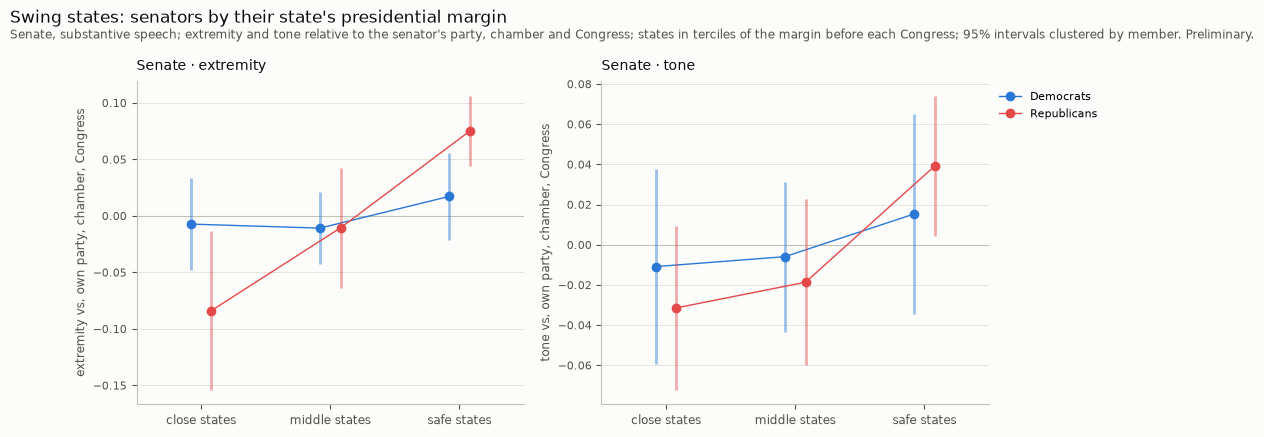

tercile                            close                   middle  \
value     party                                                     
extremity D      -0.007 [-0.048, +0.033]  -0.011 [-0.043, +0.021]   
          R      -0.084 [-0.154, -0.014]  -0.011 [-0.064, +0.042]   
tone      D      -0.011 [-0.059, +0.038]  -0.006 [-0.043, +0.031]   
          R      -0.031 [-0.072, +0.009]  -0.019 [-0.060, +0.023]   

tercile                             safe  
value     party                           
extremity D      +0.017 [-0.022, +0.056]  
          R      +0.075 [+0.044, +0.106]  
tone      D      +0.015 [-0.035, +0.065]  
          R      +0.039 [+0.004, +0.074]

Linear: per 10 points of margin (safer state), within party x Congress:


,value,party,coef_ci,p,n,n_members
0,extremity,D,"+0.031 [-0.022, +0.084]",2.502e-01,16792,123
1,extremity,R,"+0.101 [+0.048, +0.155]",2.147e-04,16087,132
2,tone,D,"+0.031 [-0.021, +0.084]",2.425e-01,16792,123
3,tone,R,"+0.044 [+0.007, +0.082]",2.108e-02,16087,132


In [19]:
shares = state_two_party_share()
check = shares.set_index(["state", "year"])["d_share"]
print(f"Two-party D share: PA 2020 = {check[('PA', 2020)]:.3f}, FL 2000 = {check[('FL', 2000)]:.3f}")
assert round(check[("PA", 2020)], 3) == 0.506 and round(check[("FL", 2000)], 3) == 0.500, "state shares off"
margins = state_margins(shares, range(FIRST_CONGRESS, LAST_CONGRESS + 1))
senate = df[df["chamber"] == "S"].assign(
    extremity_vs_cell=relative_to_cell(df, "extremity")[df["chamber"] == "S"],
    tone_vs_cell=relative_to_cell(df, "tone")[df["chamber"] == "S"],
)
senate = senate.merge(margins, on=["state", "congress_number"], how="left", validate="m:1")
print(f"Senate speeches without a margin: {senate['margin'].isna().sum()} (states: {sorted(senate.loc[senate['margin'].isna(), 'state'].unique())})")
senate = senate.dropna(subset=["margin"])
print("Senators per party and tercile (summed over Congresses):")
display(senate.groupby(["party", "tercile"])["member_key"].nunique().unstack())
swing_means, swing_linear = swing_state_effects(senate)
fig = plot_swing_states(
    swing_means,
    "Swing states: senators by their state's presidential margin",
    subtitle="Senate, substantive speech; extremity and tone relative to the senator's party, chamber and Congress; states in terciles of the margin before each Congress; 95% intervals clustered by member. Preliminary.",
)
save_figure(fig, "deepdive_swing_states")
plt.show()
display(swing_means.assign(mean_ci=with_ci(swing_means, digits=3)).pivot(
    index=["value", "party"], columns="tercile", values="mean_ci")[["close", "middle", "safe"]])
print("Linear: per 10 points of margin (safer state), within party x Congress:")
swing_linear.assign(coef_ci=with_ci(swing_linear, "coef", 3))[["value", "party", "coef_ci", "p", "n", "n_members"]]

In [20]:
tables |= {"state_margins": margins, "swing_states": swing_means, "swing_states_linear": swing_linear}

**Reading it (13).** Checks passed: PA 2020 = 0.506, FL 2000 = 0.500; every Senate speech has
a margin. 60, 63 and 50 Democratic and 58, 61 and 58 Republican senators appear in the
close, middle and safe terciles (a senator can appear in more than one).

- **Republican senators** from close states are less extreme than their party (−0.084
  [−0.154, −0.014]), those from safe states more (+0.075 [+0.044, +0.106]); per 10 points
  of margin +0.10 [+0.05, +0.16]. Tone: +0.04 [+0.01, +0.08] per 10 points; safe-state
  Republicans +0.039 [+0.004, +0.074].
- **Democratic senators:** no clear difference (extremity +0.03 [−0.02, +0.08] per 10
  points; tercile means −0.011 to +0.017).
- The House is left out (no district data).

# Part II — Topics

## D. Topics behind the jumps

**Question.** When the White House changes party, how much of the change in the
policy-debate gap comes from the parties moving within topic blocks, and how much from the
debate shifting between blocks — and which blocks carry it?

**Why.** If each new president's arrival widens the gap through a few topics, the jumps are
about the issues the new administration pushes and the opposition fights.

**How.** Notebook 08's decomposition (positions against agenda, two-factor Shapley, member
bootstrap) for each change of the White House in the data (`white_house_changes`: the
president's party differs between consecutive Congresses), per chamber; existing functions
only. The 107→118 comparison is run with it as a check that it reproduces notebook 08.
**The 114→115 step coincides with the source break** (the 114th is mixed-source); the
119th Congress covers 2025 only.

Changes of the White House: ['110→111', '114→115', '116→117', '118→119']


switch decomposition bootstrap: 5.9 min
Parts add up; 107→118 reproduces notebook 08 (values and intervals).


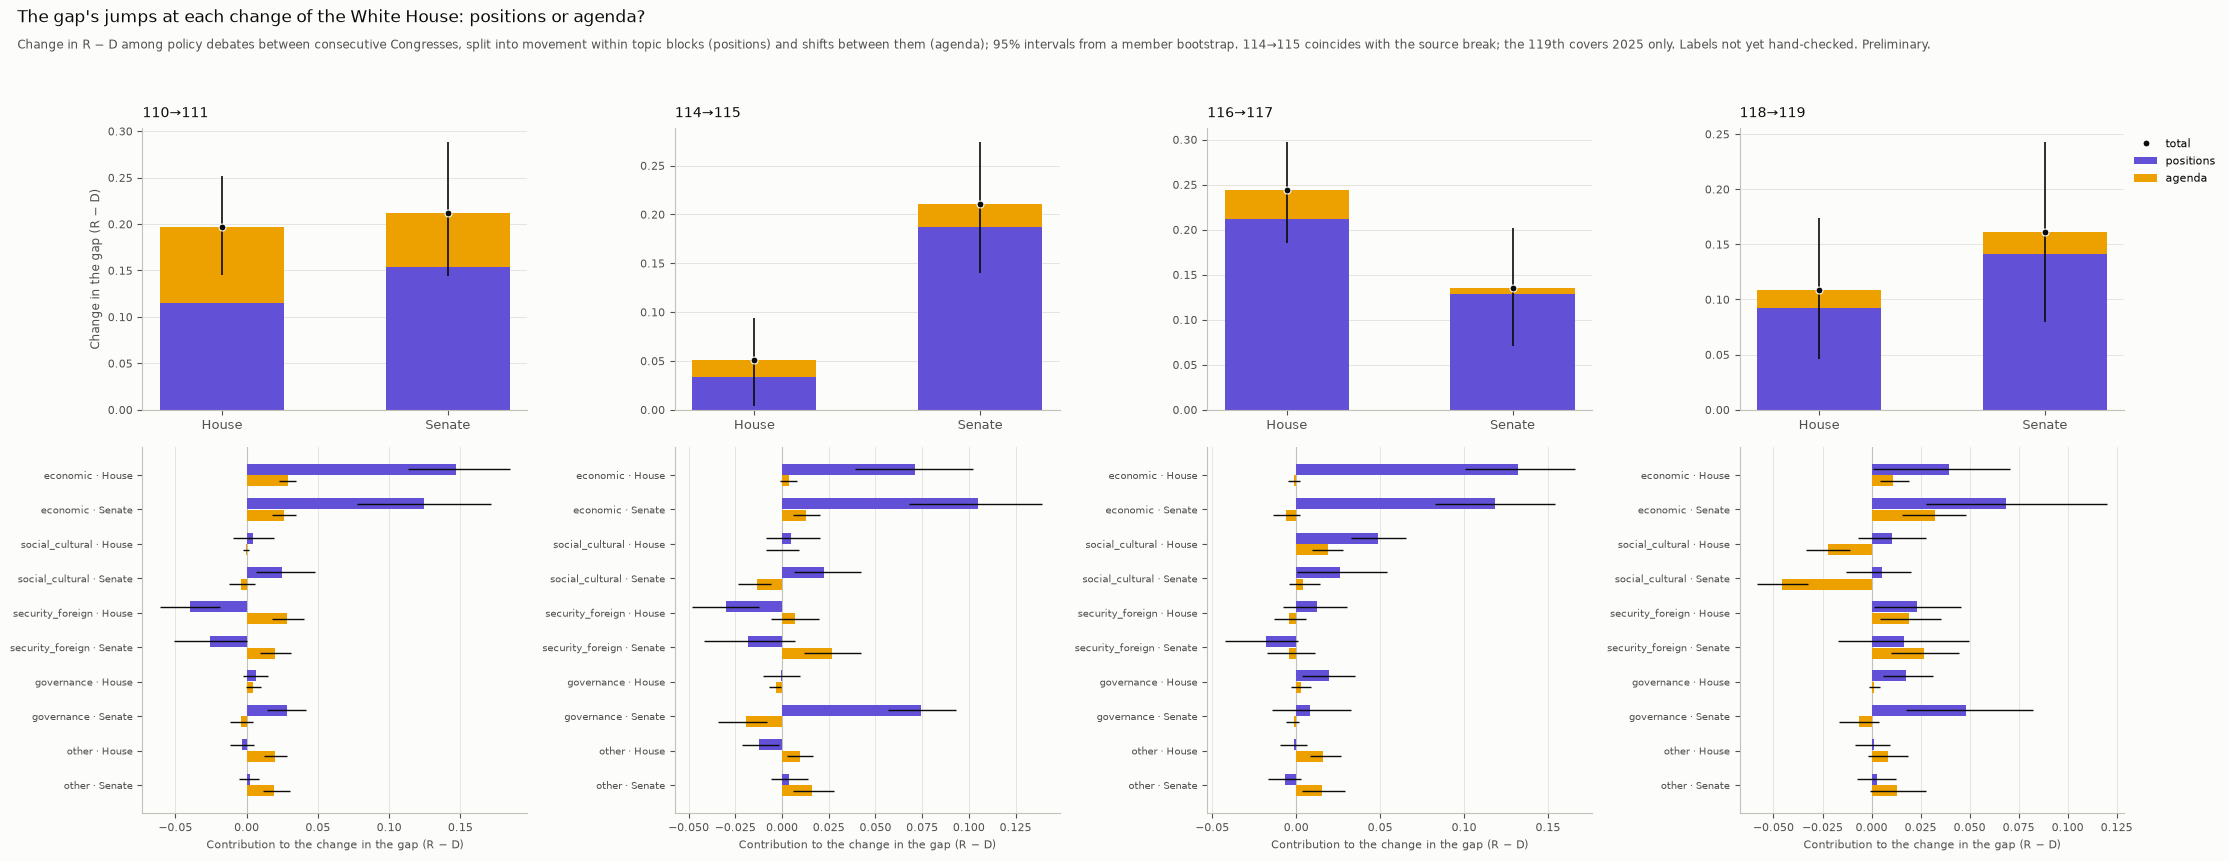

component                                             agenda  \
comparison chamber topic_block                                 
110→111    H       all               +0.082 [+0.064, +0.101]   
                   economic          +0.029 [+0.023, +0.035]   
                   governance        +0.005 [-0.000, +0.010]   
                   other             +0.020 [+0.012, +0.029]   
                   security_foreign  +0.029 [+0.018, +0.040]   
                   social_cultural   -0.000 [-0.002, +0.002]   
           S       all               +0.058 [+0.035, +0.084]   
                   economic          +0.026 [+0.018, +0.035]   
                   governance        -0.004 [-0.012, +0.005]   
                   other             +0.019 [+0.011, +0.030]   
                   security_foreign  +0.020 [+0.009, +0.031]   
                   social_cultural   -0.004 [-0.012, +0.006]   
114→115    H       all               +0.017 [-0.004, +0.036]   
                   economic          +0.004 [-0.001, +0.008]   
                   governance        -0.003 [-0.007, -0.001]   
                   other             +0.010 [+0.002, +0.016]   
                   security_foreign  +0.007 [-0.006, +0.020]   
                   social_cultural   -0.000 [-0.008, +0.009]   
           S       all               +0.023 [-0.006, +0.052]   
                   economic          +0.013 [+0.006, +0.020]   
                   governance        -0.019 [-0.034, -0.008]   
                   other             +0.016 [+0.006, +0.028]   
                   security_foreign  +0.027 [+0.012, +0.042]   
                   social_cultural   -0.013 [-0.024, -0.006]   
116→117    H       all               +0.032 [+0.013, +0.051]   
                   economic          -0.001 [-0.005, +0.002]   
                   governance        +0.003 [-0.003, +0.009]   
                   other             +0.016 [+0.008, +0.027]   
                   security_foreign  -0.004 [-0.013, +0.006]   
                   social_cultural   +0.019 [+0.009, +0.028]   
           S       all               +0.007 [-0.018, +0.034]   
                   economic          -0.006 [-0.014, +0.002]   
                   governance        -0.002 [-0.006, +0.002]   
                   other             +0.015 [+0.003, +0.029]   
                   security_foreign  -0.004 [-0.018, +0.011]   
                   social_cultural   +0.004 [-0.004, +0.014]   
118→119    H       all               +0.017 [-0.005, +0.043]   
                   economic          +0.011 [+0.004, +0.019]   
                   governance        +0.001 [-0.001, +0.004]   
                   other             +0.008 [-0.002, +0.019]   
                   security_foreign  +0.019 [+0.004, +0.035]   
                   social_cultural   -0.022 [-0.033, -0.011]   
           S       all               +0.020 [-0.016, +0.054]   
                   economic          +0.032 [+0.015, +0.048]   
                   governance        -0.006 [-0.017, +0.004]   
                   other             +0.013 [-0.001, +0.028]   
                   security_foreign  +0.027 [+0.010, +0.045]   
                   social_cultural   -0.046 [-0.058, -0.032]   

component                                          positions  \
comparison chamber topic_block                                 
110→111    H       all               +0.114 [+0.065, +0.168]   
                   economic          +0.147 [+0.113, +0.185]   
                   governance        +0.006 [-0.003, +0.015]   
                   other             -0.003 [-0.012, +0.005]   
                   security_foreign  -0.040 [-0.061, -0.019]   
                   social_cultural   +0.004 [-0.010, +0.019]   
           S       all               +0.154 [+0.088, +0.222]   
                   economic          +0.124 [+0.078, +0.172]   
                   governance        +0.029 [+0.015, +0.042]   
                   other             +0.002 [-0.005, +0.009]   
                   security_for

In [21]:
CHANGES = white_house_changes(range(FIRST_CONGRESS, LAST_CONGRESS + 1))
comparisons = {"107→118": DECOMPOSITION_COMPARISONS["107→118"], **CHANGES}
print("Changes of the White House:", list(CHANGES))
switch = timed("switch decomposition bootstrap", bootstrap_gap_decomposition, policy, comparisons,
               n_draws=DEEP_DIVE_BOOTSTRAP)

# Check: the parts add up exactly, overall and over blocks.
for (comparison, chamber), part in switch.groupby(["comparison", "chamber"]):
    total = part.query("component == 'total'")["value"].iloc[0]
    overall = part.query("topic_block == 'all' and component != 'total'")["value"].sum()
    blocks = part.query("topic_block != 'all'")["value"].sum()
    assert abs(overall - total) < 1e-12 and abs(blocks - total) < 1e-12, (comparison, chamber)
# Check: 107→118 reproduces notebook 08, intervals included (same speeches, seed and draws).
committed = pd.read_csv(METRICS_DIR / f"deepdive_gap_decomposition_{RUN}.csv")
key = ["comparison", "chamber", "component", "topic_block"]
mine = switch[switch["comparison"] == "107→118"].merge(
    committed[committed["comparison"] == "107→118"], on=key, suffixes=("", "_08"), validate="one_to_one"
)
assert len(mine) == (committed["comparison"] == "107→118").sum()
for column in ("value", "ci_low", "ci_high"):
    assert np.allclose(mine[column], mine[f"{column}_08"], rtol=0, atol=1e-12), column
print("Parts add up; 107→118 reproduces notebook 08 (values and intervals).")

fig = plot_gap_decomposition(
    switch[switch["comparison"] != "107→118"],
    "The gap's jumps at each change of the White House: positions or agenda?",
    subtitle="Change in R − D among policy debates between consecutive Congresses, split into movement within topic blocks (positions) and shifts between them (agenda); 95% intervals from a member bootstrap. 114→115 coincides with the source break; the 119th covers 2025 only. Labels not yet hand-checked. Preliminary.",
    comparisons=tuple(CHANGES),
    blocks=tuple(TOPIC_BLOCKS),
)
save_figure(fig, "deepdive_switch_decomposition")
plt.show()
blocks_shown = switch[switch["comparison"] != "107→118"]
blocks_shown.assign(value_ci=with_ci(blocks_shown, "value", 3)).pivot(
    index=["comparison", "chamber", "topic_block"], columns="component", values="value_ci"
)

In [22]:
tables["switch_decomposition"] = switch

**Reading it (D).** Checks passed: the parts add up exactly; 107→118 reproduces notebook 08,
intervals included.

- **The gap among policy debates widened at every change of the White House, in both
  chambers:** 110→111 House +0.20 [+0.15, +0.25], Senate +0.21 [+0.14, +0.29]; 114→115 House
  +0.05 [+0.00, +0.09], Senate +0.21 [+0.14, +0.27]; 116→117 House +0.24 [+0.19, +0.30],
  Senate +0.14 [+0.07, +0.20]; 118→119 House +0.11 [+0.05, +0.17], Senate +0.16 [+0.08,
  +0.24].
- **Most of each change is positions** (movement within blocks), e.g. 116→117 House +0.21 of
  +0.24. Agenda is clear only at 110→111 (House +0.08 [+0.06, +0.10], Senate +0.06 [+0.04,
  +0.08]) and at 116→117 in the House (+0.03 [+0.01, +0.05]).
- **The economic block carries the largest positions part at every change** (+0.04 to
  +0.15; e.g. 110→111 House +0.15 [+0.11, +0.19]). Governance adds in the Senate at 114→115
  (+0.07 [+0.06, +0.09]) and 118→119 (+0.05 [+0.02, +0.08]).
- 114→115 coincides with the source break; 118→119 compares a full Congress with 2025 only.

## E. Topic tests to the last Congress

**Question.** Which topic blocks' party gap widened from the 107th to the last Congress
in the data, and is that the same answer as to the last complete Congress?

**Why.** It tells which issues the parties pulled apart on, using the newest data.

**How.** Notebook 08's topic model (saturated party × block × Congress, clustered by member)
and its tests (`topic_gap_tests`): the change in each block's gap, and a joint Wald test
that all blocks changed alike. Main comparison 107 → last Congress (currently the 119th,
2025 only); the last complete Congress (currently the 118th, notebook 08's comparison) as
the control. Notebook 08's table stays as it is; the 107→118 rows here must reproduce it.

In [23]:
sizes = topic_cell_sizes(policy)
small = sizes[sizes["below_min"]]
print(f"{len(small)} of {len(sizes)} topic cells under {TOPIC_MIN_CELL} policy debates")
if len(small):
    display(small)
    raise RuntimeError("topic cells under the minimum: review them")
fits = {chamber: fit_topic_model(policy, chamber) for chamber in ("H", "S")}
spans = {"main": (FIRST_CONGRESS, LAST_CONGRESS), "control": (FIRST_CONGRESS, LAST_COMPLETE)}
topic_tests_last = pd.concat(
    [topic_gap_tests(fit, chamber, span).assign(comparison=name)
     for name, span in spans.items() for chamber, fit in fits.items()],
    ignore_index=True,
)
committed = pd.read_csv(METRICS_DIR / f"deepdive_topic_gap_tests_{RUN}.csv")
control = topic_tests_last[topic_tests_last["span"] == "107-118"].drop(columns="comparison")
check = control.merge(committed, on=["chamber", "topic_block", "span"], suffixes=("", "_08"))
assert len(check) == len(committed)
for column in ("change", "se", "chi2", "p"):
    assert np.allclose(check[column], check[f"{column}_08"], rtol=1e-10, equal_nan=True), column
print("107→118 reproduces notebook 08.")
shown = topic_tests_last[topic_tests_last["topic_block"] != "all (joint)"]
display(shown.assign(change_ci=with_ci(shown, "change", 3)).pivot(
    index=["chamber", "topic_block"], columns="span", values=["change_ci", "p"]))
topic_tests_last[topic_tests_last["topic_block"] == "all (joint)"][["chamber", "span", "chi2", "df", "p"]]

0 of 260 topic cells under 30 policy debates


107→118 reproduces notebook 08.


change_ci                           \
span                                      107-118                  107-119   
chamber topic_block                                                          
H       economic          +0.470 [+0.377, +0.564]  +0.555 [+0.458, +0.652]   
        governance        +0.454 [+0.303, +0.604]  +0.641 [+0.486, +0.796]   
        other             +0.029 [-0.092, +0.151]  +0.059 [-0.069, +0.187]   
        security_foreign  +0.210 [+0.109, +0.311]  +0.335 [+0.208, +0.463]   
        social_cultural   +0.502 [+0.362, +0.642]  +0.558 [+0.413, +0.704]   
S       economic          +0.477 [+0.332, +0.622]  +0.656 [+0.539, +0.772]   
        governance        +0.408 [+0.287, +0.528]  +0.605 [+0.484, +0.725]   
        other             -0.021 [-0.179, +0.137]  +0.020 [-0.181, +0.222]   
        security_foreign  +0.382 [+0.224, +0.539]  +0.469 [+0.326, +0.613]   
        social_cultural   +0.945 [+0.586, +1.303]  +0.975 [+0.610, +1.340]   

                               p          
span                     107-118 107-119  
chamber topic_block                       
H       economic             0.0     0.0  
        governance           0.0     0.0  
        other              0.636   0.368  
        security_foreign     0.0     0.0  
        social_cultural      0.0     0.0  
S       economic             0.0     0.0  
        governance           0.0     0.0  
        other              0.793   0.843  
        security_foreign     0.0     0.0  
        social_cultural      0.0     0.0

,chamber,span,chi2,df,p
5,H,107-119,60.160,4.0,2.684e-12
11,S,107-119,42.711,4.0,1.188e-08
17,H,107-118,50.890,4.0,2.354e-10
23,S,107-118,41.807,4.0,1.829e-08


In [24]:
tables["topic_gap_tests_to_last"] = topic_tests_last

**Reading it (E).** Checks passed: 107→118 reproduces notebook 08; no topic cell under 30.

- **107→119: the gap widened in every block except "other", in both chambers.** House:
  governance +0.64 [+0.49, +0.80], social-cultural +0.56 [+0.41, +0.70], economic +0.56
  [+0.46, +0.65], security/foreign +0.34 [+0.21, +0.46]. Senate: social-cultural +0.98
  [+0.61, +1.34], economic +0.66 [+0.54, +0.77], governance +0.61 [+0.48, +0.73],
  security/foreign +0.47 [+0.33, +0.61]. "Other": +0.06 and +0.02, intervals across zero.
- **Each change is larger to the 119th than to the 118th.** The Senate's order of blocks is
  the same; in the House, governance moves from third (+0.45) to first.
- **The blocks did not change alike** (joint test, 4 df: House χ² = 60.2, Senate 42.7,
  p < 10⁻⁷).

## 1. Common ground

**Question.** How much do Democratic and Republican speeches still overlap — overall and
within each topic block?

**Why.** The gap between means can widen while many speeches still meet in the middle; the
overlap says how much shared ground is left for agreement.

**How.** Per Congress and chamber (and topic block): the share of Democratic speeches to
the right of the Republican median speech, the share of Republican speeches to the left of
the Democratic median, and the overlap coefficient of the two distributions, Σ min(p_D(v),
p_R(v)) over the observed scores (0 = no overlap, 1 = identical; exact, since scores lie on
a 0.05 grid). Overall = all substantive speeches; blocks = policy debates. Intervals from a
member bootstrap within party (1,000 draws). **Limits:** strict inequalities, and many
speeches score exactly 0.0, so a median at 0.0 makes the crossing shares jump; speeches,
not members.

common ground bootstrap (all): 2.1 min


common ground bootstrap (blocks): 5.0 min


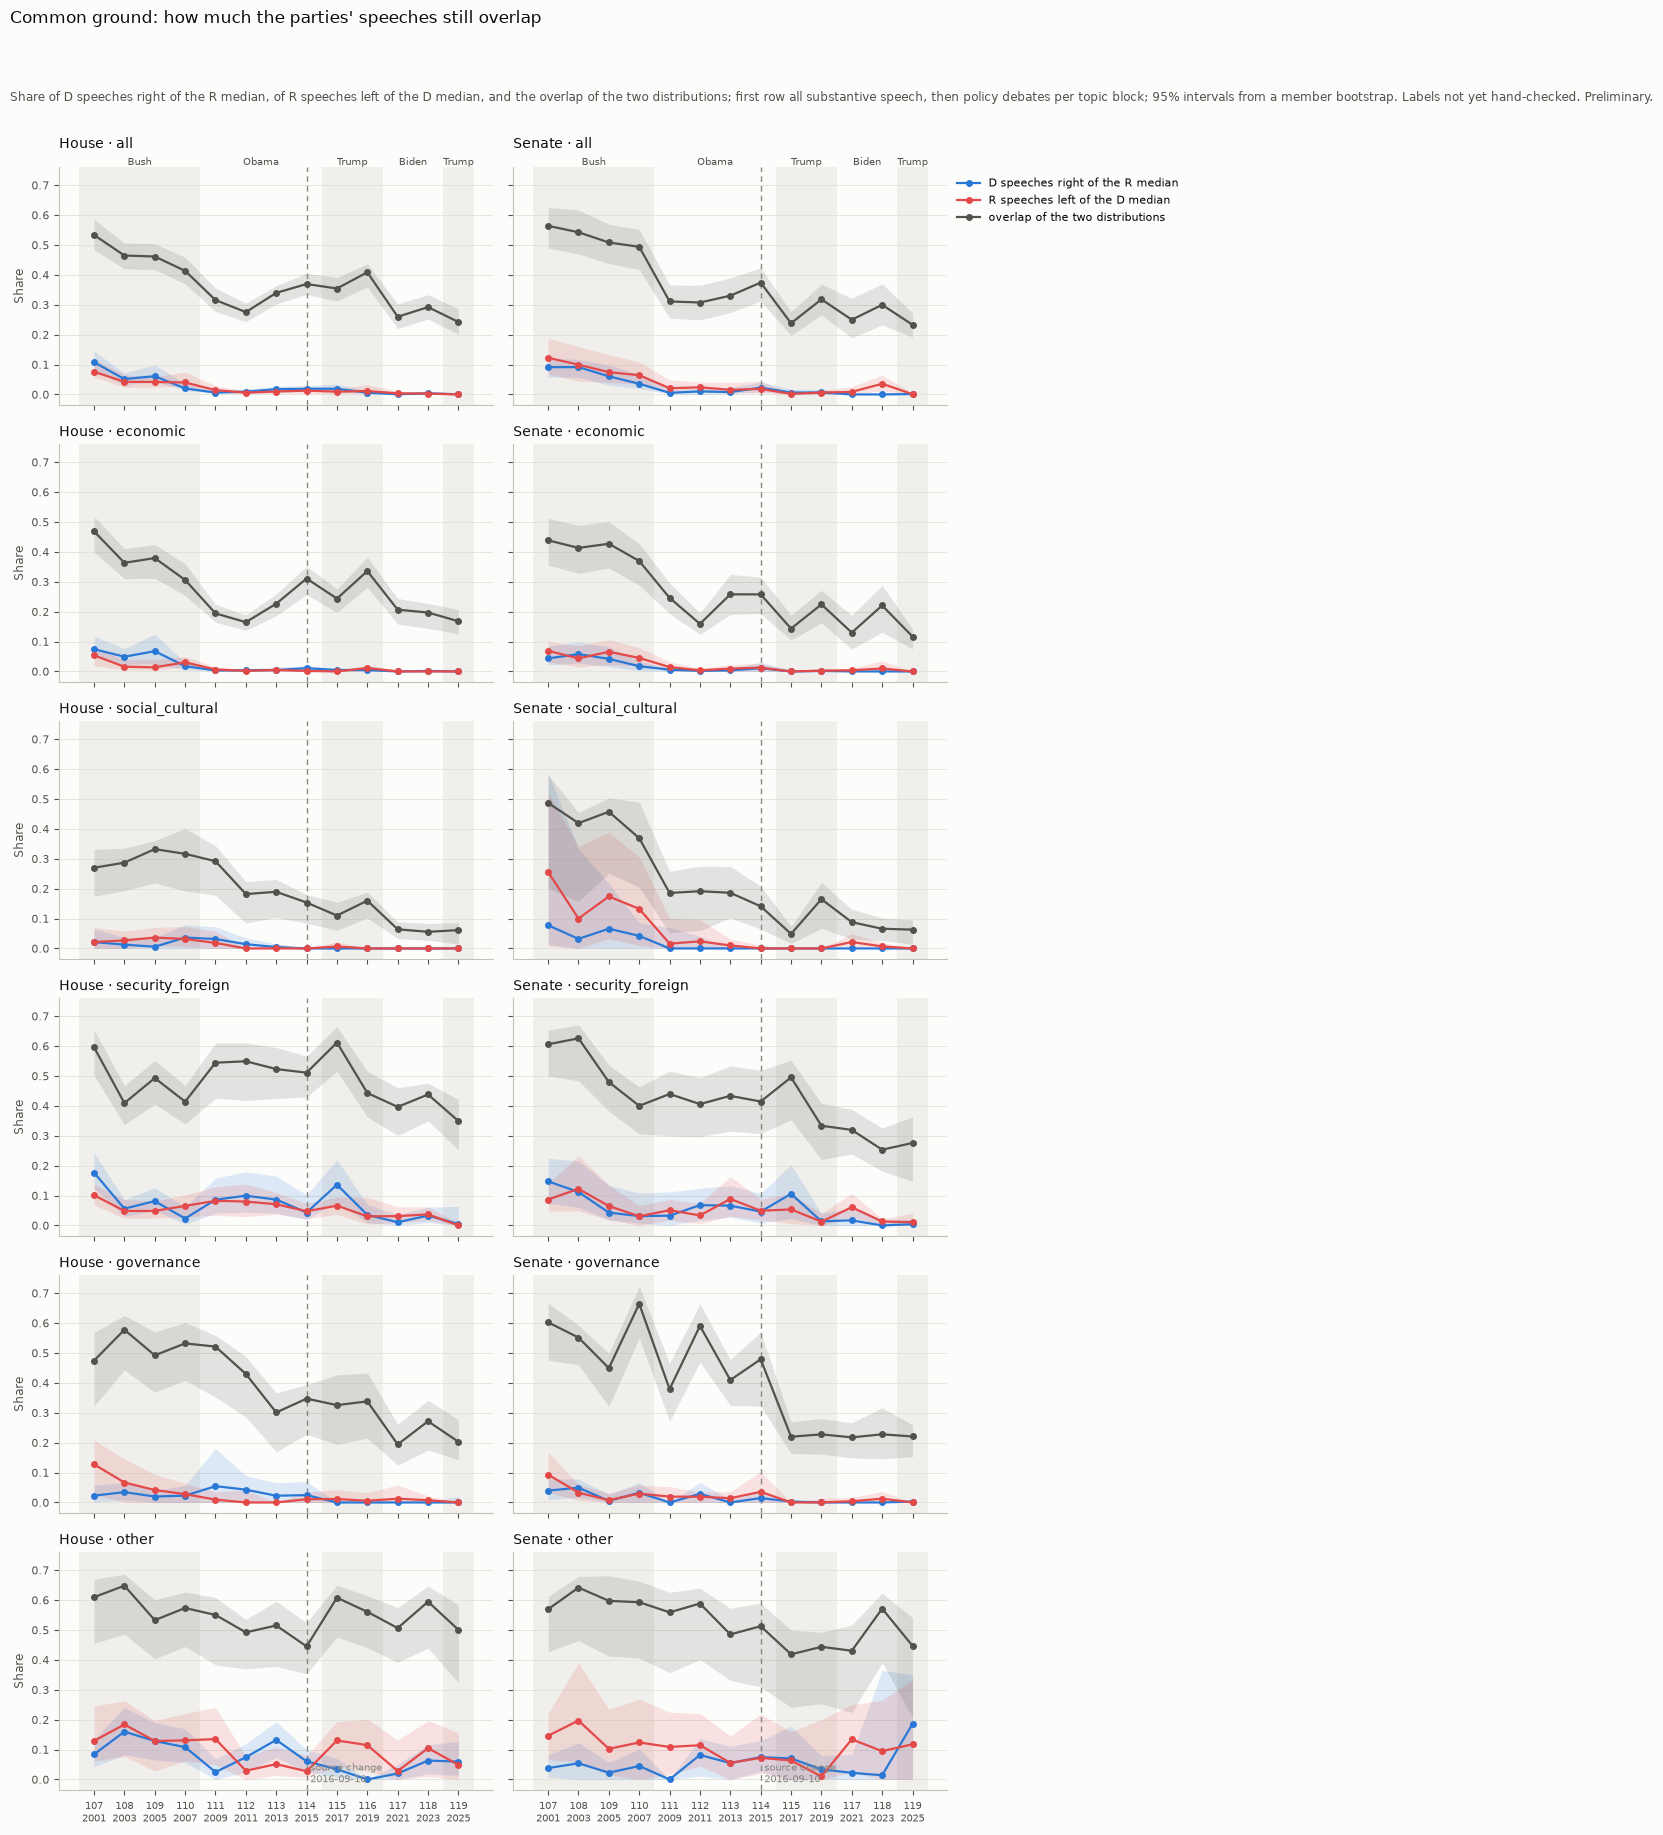

chamber                                H                           \
measure              d_right_of_r_median       r_left_of_d_median   
congress_number                                                     
107              +0.108 [+0.080, +0.144]  +0.076 [+0.059, +0.119]   
108              +0.051 [+0.032, +0.072]  +0.042 [+0.024, +0.066]   
109              +0.061 [+0.045, +0.099]  +0.042 [+0.024, +0.059]   
110              +0.020 [+0.013, +0.035]  +0.040 [+0.028, +0.075]   
111              +0.006 [+0.003, +0.015]  +0.015 [+0.009, +0.030]   
112              +0.009 [+0.004, +0.019]  +0.006 [+0.002, +0.011]   
113              +0.018 [+0.007, +0.027]  +0.010 [+0.004, +0.018]   
114              +0.019 [+0.011, +0.030]  +0.013 [+0.004, +0.023]   
115              +0.019 [+0.010, +0.035]  +0.009 [+0.002, +0.017]   
116              +0.006 [+0.003, +0.013]  +0.011 [+0.006, +0.032]   
117              +0.001 [+0.000, +0.004]  +0.004 [+0.001, +0.011]   
118              +0.003 [+0.001, +0.009]  +0.003 [+0.001, +0.007]   
119              +0.001 [+0.000, +0.005]  +0.000 [+0.000, +0.005]   

chamber                                                         S  \
measure                          overlap      d_right_of_r_median   
congress_number                                                     
107              +0.533 [+0.484, +0.585]  +0.091 [+0.057, +0.122]   
108              +0.465 [+0.420, +0.507]  +0.091 [+0.058, +0.117]   
109              +0.461 [+0.417, +0.505]  +0.061 [+0.031, +0.098]   
110              +0.413 [+0.370, +0.458]  +0.036 [+0.020, +0.068]   
111              +0.316 [+0.277, +0.355]  +0.005 [+0.001, +0.017]   
112              +0.275 [+0.243, +0.305]  +0.010 [+0.000, +0.021]   
113              +0.340 [+0.302, +0.364]  +0.008 [+0.003, +0.024]   
114              +0.369 [+0.335, +0.405]  +0.023 [+0.008, +0.042]   
115              +0.354 [+0.312, +0.391]  +0.006 [+0.001, +0.018]   
116              +0.409 [+0.360, +0.437]  +0.007 [+0.000, +0.016]   
117              +0.260 [+0.221, +0.303]  +0.000 [+0.000, +0.002]   
118              +0.292 [+0.252, +0.334]  +0.000 [+0.000, +0.004]   
119              +0.242 [+0.201, +0.286]  +0.001 [+0.000, +0.005]   

chamber                                                            
measure               r_left_of_d_median                  overlap  
congress_number                                                    
107              +0.123 [+0.069, +0.187]  +0.564 [+0.490, +0.625]  
108              +0.100 [+0.044, +0.160]  +0.542 [+0.470, +0.617]  
109              +0.074 [+0.040, +0.133]  +0.508 [+0.438, +0.569]  
110              +0.064 [+0.035, +0.109]  +0.494 [+0.417, +0.552]  
111              +0.021 [+0.009, +0.048]  +0.311 [+0.255, +0.366]  
112              +0.024 [+0.011, +0.042]  +0.307 [+0.250, +0.365]  
113              +0.016 [+0.005, +0.040]  +0.330 [+0.274, +0.390]  
114              +0.019 [+0.006, +0.044]  +0.374 [+0.312, +0.423]  
115              +0.002 [+0.000, +0.005]  +0.238 [+0.197, +0.276]  
116              +0.006 [+0.001, +0.014]  +0.318 [+0.267, +0.369]  
117              +0.009 [+0.003, +0.026]  +0.250 [+0.189, +0.322]  
118              +0.036 [+0.012, +0.065]  +0.300 [+0.232, +0.370]  
119              +0.001 [+0.000, +0.003]  +0.233 [+0.192, +0.272]

In [25]:
ground_all = timed("common ground bootstrap (all)", bootstrap_common_ground, df,
                   ("congress_number", "chamber")).assign(topic_block="all")
ground_blocks = timed("common ground bootstrap (blocks)", bootstrap_common_ground, policy,
                      ("congress_number", "chamber", "topic_block"))
ground = pd.concat([ground_all, ground_blocks], ignore_index=True)
fig = plot_common_ground(
    ground, ["all", *TOPIC_BLOCKS],
    "Common ground: how much the parties' speeches still overlap",
    subtitle="Share of D speeches right of the R median, of R speeches left of the D median, and the overlap of the two distributions; first row all substantive speech, then policy debates per topic block; 95% intervals from a member bootstrap. Labels not yet hand-checked. Preliminary.",
)
save_figure(fig, "deepdive_common_ground")
plt.show()
shown = ground[ground["topic_block"] == "all"]
shown.assign(value_ci=with_ci(shown, "value", 3)).pivot(
    index="congress_number", columns=["chamber", "measure"], values="value_ci"
)

In [26]:
tables["common_ground"] = ground

**Reading it (1).**

- **House:** the share of Democratic speeches right of the Republican median fell from 10.8%
  [8.0, 14.4] (107th) to 0.1% [0.0, 0.5] (119th); Republican speeches left of the
  Democratic median from 7.6% [5.9, 11.9] to 0.0% [0.0, 0.5]. The overlap fell from 0.53
  [0.48, 0.58] to 0.24 [0.20, 0.29].
- **Senate:** 9.1% → 0.1% and 12.3% → 0.1%; overlap 0.56 [0.49, 0.62] → 0.23 [0.19, 0.27].
- The largest single step is from the 110th to the 111th (overlap House 0.41 → 0.32,
  Senate 0.49 → 0.31); the 114th and 116th sit higher than their neighbours.
- **By block (overlap, 107th → 119th):** social-cultural is lowest and nearly gone (House
  0.27 → 0.06, Senate 0.49 → 0.06); economic House 0.47 → 0.17, Senate 0.44 → 0.12;
  governance 0.47 → 0.20 and 0.60 → 0.22; security/foreign keeps the most of the four
  (0.60 → 0.35 and 0.61 → 0.28); "other" changes little (0.61 → 0.50, 0.57 → 0.45, wide
  intervals).

# Part III — Hostility

## G. Tone by topic

**Question.** In which topic blocks did each party's tone harden from the 107th to the last
Congress?

**Why.** If hostility rises mostly in a few blocks, the conflict is concentrated in
specific issues; if it rises everywhere, it is a general change in how the parties speak to
each other.

**How.** The same saturated model as section E (party × block × Congress, clustered by
member), for tone instead of ideology; each party's mean per block and Congress, and the
change per party and block from the 107th to the last Congress (main) and to the last
complete Congress (control), with a joint test per party that all blocks changed alike
(`topic_party_change_tests`). **Note:** tone and ideology come from the same model and the
same call, so they are not independent measurements.

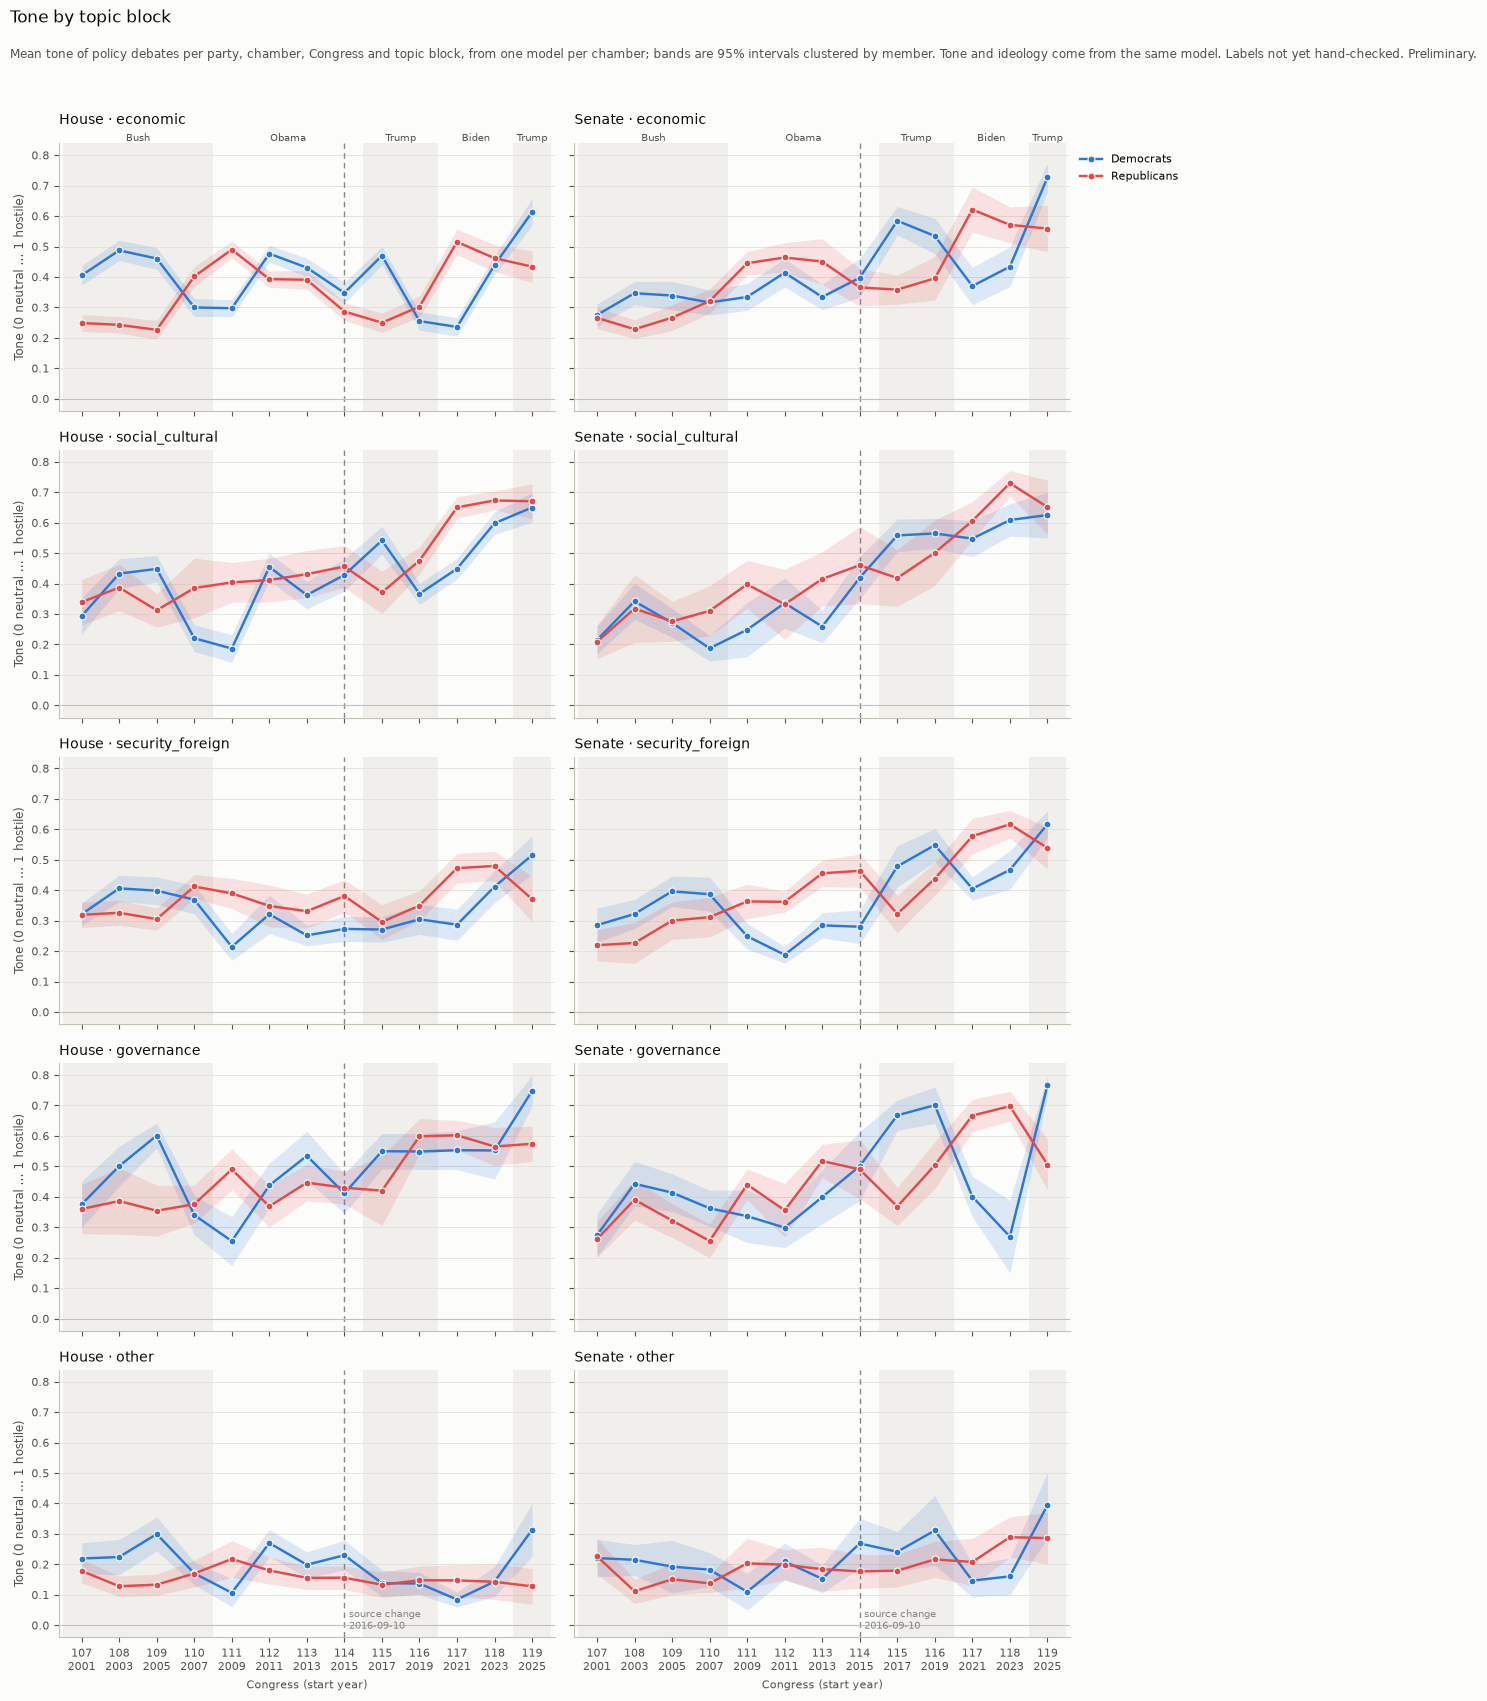

span                                            107-118  \
chamber party topic_block                                 
H       D     economic          +0.034 [-0.009, +0.077]   
              governance        +0.177 [+0.064, +0.290]   
              other             -0.076 [-0.145, -0.007]   
              security_foreign  +0.091 [+0.027, +0.154]   
              social_cultural   +0.305 [+0.234, +0.377]   
        R     economic          +0.213 [+0.161, +0.264]   
              governance        +0.205 [+0.103, +0.308]   
              other             -0.035 [-0.105, +0.035]   
              security_foreign  +0.160 [+0.097, +0.224]   
              social_cultural   +0.334 [+0.254, +0.415]   
S       D     economic          +0.159 [+0.091, +0.226]   
              governance        -0.005 [-0.142, +0.132]   
              other             -0.060 [-0.145, +0.025]   
              security_foreign  +0.182 [+0.099, +0.265]   
              social_cultural   +0.394 [+0.328, +0.460]   
        R     economic          +0.305 [+0.236, +0.374]   
              governance        +0.437 [+0.370, +0.504]   
              other             +0.063 [-0.025, +0.151]   
              security_foreign  +0.397 [+0.337, +0.458]   
              social_cultural   +0.521 [+0.452, +0.590]   

span                                            107-119  
chamber party topic_block                                
H       D     economic          +0.208 [+0.152, +0.263]  
              governance        +0.373 [+0.279, +0.467]  
              other             +0.094 [-0.007, +0.195]  
              security_foreign  +0.194 [+0.121, +0.268]  
              social_cultural   +0.357 [+0.281, +0.433]  
        R     economic          +0.185 [+0.126, +0.244]  
              governance        +0.214 [+0.114, +0.314]  
              other             -0.051 [-0.121, +0.020]  
              security_foreign  +0.051 [-0.034, +0.137]  
              social_cultural   +0.332 [+0.239, +0.424]  
S       D     economic          +0.452 [+0.393, +0.510]  
              governance        +0.492 [+0.416, +0.568]  
              other             +0.174 [+0.046, +0.301]  
              security_foreign  +0.332 [+0.259, +0.404]  
              social_cultural   +0.411 [+0.329, +0.493]  
        R     economic          +0.293 [+0.206, +0.380]  
              governance        +0.245 [+0.143, +0.348]  
              other             +0.060 [-0.039, +0.159]  
              security_foreign  +0.320 [+0.239, +0.400]  
              social_cultural   +0.442 [+0.338, +0.547]

,chamber,party,span,chi2,df,p
5,H,D,107-119,32.060,4.0,1.860e-06
11,H,R,107-119,71.417,4.0,1.140e-14
17,S,D,107-119,40.156,4.0,4.019e-08
23,S,R,107-119,33.674,4.0,8.692e-07
29,H,D,107-118,67.811,4.0,6.575e-14
35,H,R,107-118,55.788,4.0,2.222e-11
41,S,D,107-118,81.269,4.0,9.380e-17
47,S,R,107-118,90.607,4.0,9.785e-19


In [27]:
tone_fits = {chamber: fit_topic_model(policy, chamber, value="tone") for chamber in ("H", "S")}
tone_values = pd.concat([topic_party_values(fit, chamber) for chamber, fit in tone_fits.items()],
                        ignore_index=True)
fig = plot_party_positions_by_group(
    tone_values, "topic_block", "Tone (0 neutral … 1 hostile)",
    "Tone by topic block",
    subtitle="Mean tone of policy debates per party, chamber, Congress and topic block, from one model per chamber; bands are 95% intervals clustered by member. Tone and ideology come from the same model. Labels not yet hand-checked. Preliminary.",
    order=tuple(TOPIC_BLOCKS),
)
save_figure(fig, "deepdive_tone_by_topic")
plt.show()
tone_tests = pd.concat(
    [topic_party_change_tests(fit, chamber, span).assign(comparison=name)
     for name, span in spans.items() for chamber, fit in tone_fits.items()],
    ignore_index=True,
)
shown = tone_tests[tone_tests["topic_block"] != "all (joint)"]
display(shown.assign(change_ci=with_ci(shown, "change", 3)).pivot(
    index=["chamber", "party", "topic_block"], columns="span", values="change_ci"))
tone_tests[tone_tests["topic_block"] == "all (joint)"][["chamber", "party", "span", "chi2", "df", "p"]]

In [28]:
tables |= {"tone_by_topic": tone_values, "tone_topic_tests": tone_tests}

**Reading it (G).** Tone and ideology come from the same model.

- **Tone rose from the 107th to the 119th in most blocks for both parties.** House Democrats
  +0.19 to +0.37 in four blocks (governance +0.37 [+0.28, +0.47], social-cultural +0.36
  [+0.28, +0.43]); House Republicans social-cultural +0.33 [+0.24, +0.42], governance +0.21,
  economic +0.19, security/foreign not clear (+0.05 [−0.03, +0.14]); Senate Democrats +0.33
  to +0.49 in four blocks (governance +0.49 [+0.42, +0.57], economic +0.45 [+0.39, +0.51]);
  Senate Republicans +0.25 to +0.44 (social-cultural +0.44 [+0.34, +0.55]). "Other"
  changed least (−0.05 to +0.17).
- **Social-cultural rose clearly for every party and chamber in both comparisons** (+0.31 to
  +0.52).
- **To the 118th, Republicans' rises are mostly larger than to the 119th** (Senate governance
  +0.44 against +0.25, security/foreign +0.40 against +0.32) **and Democrats' smaller**
  (Senate economic +0.16 against +0.45). In the 119th Democrats are out of the White House;
  it covers 2025 only.
- **The blocks did not change alike for any party** (joint tests, p < 10⁻⁵).

## 6. Cooperation and enemy words

**Question.** Has the language of cooperation given way to the language of enemies?

**Why.** It is the most direct trace in the record of parties fighting each other instead
of working together.

**How.** Two lists that passed the hand check: `cooperation` (86% true hits: bipartisan,
compromise, common ground, across the aisle, working together …) and `hostility`
(second version, 80%: socialist/socialism, radical/far left and right, radical or extremist
agenda, environmental extremists …; most false hits are "socialism" in denials, general
statements and quotations). The share of substantive speeches with at least one hit per
party, chamber and **Congress** (the hostility list is too rare for yearly lines: 6–38
speeches a year before 2017), both lists in one panel; yearly values with n in the table
only. Robustness: the same on the whole corpus. **Limits:** the cooperation list also
catches routine phrases ("bipartisan bill"); a hit is not a stance.

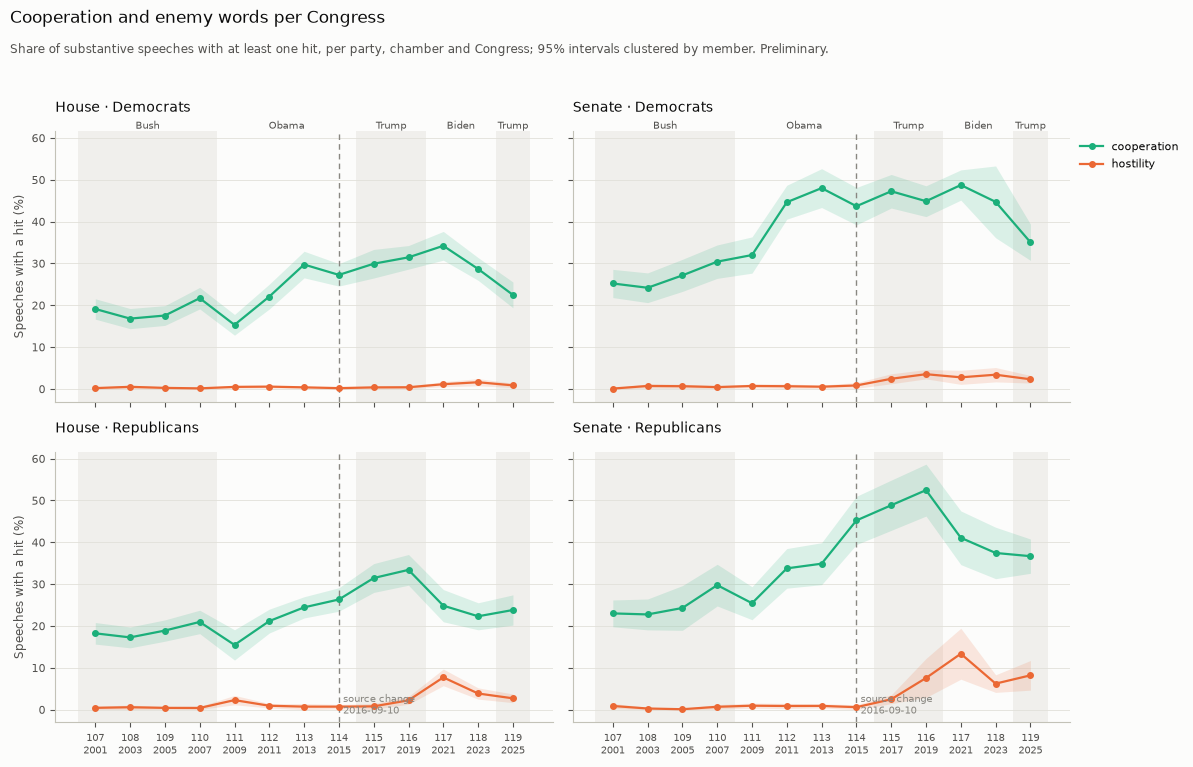

list                    cooperation                                          \
chamber                           H                                       S   
party                             D                   R                   D   
congress_number                                                               
107              19.1% [16.7, 21.5]  18.2% [15.7, 20.8]  25.2% [21.8, 28.6]   
108              16.8% [14.4, 19.2]  17.3% [14.8, 19.8]  24.2% [20.6, 27.7]   
109              17.5% [15.2, 19.9]  18.9% [16.4, 21.4]  27.1% [23.3, 31.0]   
110              21.7% [19.1, 24.3]  21.0% [18.2, 23.8]  30.4% [26.4, 34.4]   
111              15.3% [12.8, 17.8]  15.5% [11.8, 19.1]  32.0% [27.7, 36.3]   
112              22.1% [19.1, 25.0]  21.2% [18.3, 24.0]  44.6% [40.6, 48.7]   
113              29.7% [26.6, 32.9]  24.4% [21.9, 27.0]  48.0% [43.4, 52.7]   
114              27.3% [24.6, 29.9]  26.3% [23.5, 29.1]  43.7% [39.2, 48.2]   
115              29.9% [26.5, 33.3]  31.5% [28.0, 34.9]  47.3% [43.2, 51.3]   
116              31.5% [28.6, 34.3]  33.4% [29.7, 37.1]  44.9% [41.2, 48.6]   
117              34.2% [30.8, 37.7]  24.9% [21.0, 28.7]  48.7% [45.1, 52.4]   
118              28.7% [26.0, 31.4]  22.3% [19.1, 25.5]  44.7% [36.1, 53.3]   
119              22.5% [19.4, 25.6]  23.8% [20.2, 27.4]  35.1% [30.7, 39.4]   

list                                        hostility                    \
chamber                                             H                     
party                             R                 D                 R   
congress_number                                                           
107              23.0% [19.8, 26.2]  0.2% [-0.0, 0.4]   0.4% [0.0, 0.8]   
108              22.8% [19.1, 26.4]   0.5% [0.1, 0.9]   0.6% [0.1, 1.1]   
109              24.3% [19.0, 29.6]   0.2% [0.0, 0.5]   0.4% [0.1, 0.7]   
110              29.8% [24.8, 34.7]  0.1% [-0.1, 0.3]   0.4% [0.0, 0.8]   
111              25.4% [21.5, 29.4]   0.5% [0.1, 0.8]   2.3% [1.2, 3.4]   
112              33.8% [29.0, 38.5]   0.6% [0.2, 0.9]   0.9% [0.4, 1.5]   
113              34.9% [29.9, 39.9]   0.4% [0.1, 0.7]  0.7% [-0.0, 1.4]   
114              45.2% [39.5, 51.0]  0.2% [-0.0, 0.4]   0.7% [0.2, 1.2]   
115              48.9% [42.9, 54.9]   0.4% [0.0, 0.7]   0.8% [0.1, 1.5]   
116              52.5% [46.3, 58.7]   0.4% [0.1, 0.7]   2.2% [1.3, 3.1]   
117              41.1% [34.7, 47.5]   1.1% [0.5, 1.7]   7.7% [5.7, 9.7]   
118              37.5% [31.3, 43.6]   1.6% [0.7, 2.5]   3.9% [2.5, 5.2]   
119              36.7% [32.6, 40.8]   0.9% [0.3, 1.4]   2.7% [1.7, 3.7]   

list                                                  
chamber                         S                     
party                           D                  R  
congress_number                                       
107              0.1% [-0.1, 0.2]    0.9% [0.3, 1.5]  
108               0.7% [0.2, 1.2]   0.3% [-0.0, 0.5]  
109               0.6% [0.2, 1.1]   0.1% [-0.1, 0.3]  
110               0.4% [0.1, 0.8]    0.7% [0.1, 1.2]  
111               0.7% [0.2, 1.2]    0.9% [0.3, 1.6]  
112               0.6% [0.1, 1.2]    0.9% [0.2, 1.5]  
113               0.5% [0.1, 0.9]    0.9% [0.4, 1.4]  
114               0.8% [0.1, 1.5]   0.6% [-0.0, 1.2]  
115               2.4% [1.2, 3.6]    2.5% [1.4, 3.5]  
116               3.5% [2.4, 4.6]   7.6% [2.9, 12.2]  
117               2.8% [1.1, 4.5]  13.4% [7.3, 19.5]  
118               3.4% [1.7, 5.1]    6.2% [4.1, 8.3]  
119               2.3% [1.4, 3.2]   8.2% [4.7, 11.7]

In [29]:
WORDS = ["cooperation", "hostility"]
words = keyword_shares(df, hits, WORDS, by=("congress_number", "chamber", "party"))
words_yearly = keyword_shares(df.assign(year=YEAR), hits, WORDS, by=("year", "chamber", "party"))
fig = plot_keyword_lines_by_congress(
    words, WORDS,
    "Cooperation and enemy words per Congress",
    subtitle="Share of substantive speeches with at least one hit, per party, chamber and Congress; 95% intervals clustered by member. Preliminary.",
)
save_figure(fig, "deepdive_cooperation_hostility")
plt.show()
words.assign(share=pct_ci(words)).pivot(index="congress_number", columns=["list", "chamber", "party"], values="share")

In [30]:
words_corpus = keyword_shares(corpus, corpus_flags, WORDS, by=("congress_number", "chamber", "party"))
print("Robustness, whole corpus (share of speeches with a hit):")
display(words_corpus.assign(share=pct_ci(words_corpus)).pivot(
    index="congress_number", columns=["list", "chamber", "party"], values="share"))
tables |= {"cooperation_hostility": words, "cooperation_hostility_yearly": words_yearly,
           "cooperation_hostility_corpus": words_corpus}

Robustness, whole corpus (share of speeches with a hit):


list                    cooperation                                          \
chamber                           H                                       S   
party                             D                   R                   D   
congress_number                                                               
107              17.8% [16.3, 19.2]  15.9% [14.4, 17.3]  17.6% [13.2, 21.9]   
108              16.0% [14.6, 17.4]  14.6% [13.3, 15.8]  19.2% [15.5, 22.9]   
109              15.7% [14.2, 17.2]  16.0% [14.6, 17.4]  22.9% [20.3, 25.5]   
110              19.2% [18.0, 20.5]  19.5% [17.7, 21.3]  21.3% [19.3, 23.4]   
111              14.9% [13.7, 16.2]  15.1% [12.9, 17.3]  21.0% [17.7, 24.3]   
112              22.5% [20.2, 24.9]  19.4% [17.7, 21.1]  28.6% [23.7, 33.6]   
113              26.3% [24.1, 28.4]  21.7% [20.1, 23.3]  31.1% [24.9, 37.3]   
114              25.5% [23.8, 27.2]  21.2% [19.6, 22.8]  36.3% [33.0, 39.6]   
115              27.1% [25.0, 29.2]  23.7% [21.8, 25.7]  42.4% [39.3, 45.6]   
116              26.9% [25.0, 28.8]  27.6% [24.8, 30.3]  39.9% [36.2, 43.7]   
117              27.6% [25.2, 30.1]  20.0% [18.0, 22.1]  33.0% [30.0, 36.0]   
118              25.3% [23.2, 27.5]  17.1% [15.3, 19.0]  30.5% [26.5, 34.4]   
119              19.7% [17.3, 22.1]  16.1% [14.0, 18.1]  31.4% [27.0, 35.8]   

list                                       hostility                   \
chamber                                            H                    
party                             R                D                R   
congress_number                                                         
107              18.7% [16.1, 21.3]  0.2% [0.1, 0.3]  0.4% [0.2, 0.7]   
108              14.9% [12.5, 17.3]  0.2% [0.1, 0.2]  0.5% [0.3, 0.6]   
109              16.5% [14.2, 18.9]  0.2% [0.1, 0.2]  0.3% [0.2, 0.4]   
110              23.2% [19.9, 26.4]  0.2% [0.1, 0.3]  0.6% [0.4, 0.9]   
111              20.9% [17.9, 23.9]  0.3% [0.2, 0.5]  1.8% [0.9, 2.7]   
112              25.7% [22.2, 29.1]  0.6% [0.4, 0.7]  0.5% [0.3, 0.7]   
113              27.3% [23.6, 30.9]  0.2% [0.1, 0.3]  0.4% [0.2, 0.6]   
114              29.3% [26.2, 32.5]  0.2% [0.1, 0.2]  0.3% [0.2, 0.5]   
115              32.5% [27.5, 37.4]  0.3% [0.2, 0.4]  0.5% [0.2, 0.8]   
116              36.1% [31.5, 40.8]  0.3% [0.2, 0.4]  2.1% [1.5, 2.8]   
117              33.0% [26.0, 40.0]  0.7% [0.5, 0.9]  4.8% [3.9, 5.7]   
118              28.0% [20.8, 35.2]  1.8% [1.4, 2.3]  2.8% [2.1, 3.6]   
119              22.9% [18.5, 27.3]  0.7% [0.3, 1.0]  2.1% [1.6, 2.6]   

list                                                 
chamber                        S                     
party                          D                  R  
congress_number                                      
107              0.2% [0.1, 0.3]    0.4% [0.2, 0.5]  
108              0.4% [0.2, 0.7]    0.3% [0.1, 0.5]  
109              0.7% [0.4, 0.9]    0.3% [0.2, 0.5]  
110              0.2% [0.1, 0.3]    0.4% [0.2, 0.6]  
111              0.3% [0.2, 0.5]    0.6% [0.2, 0.9]  
112              0.4% [0.2, 0.6]    0.6% [0.3, 0.9]  
113              0.4% [0.2, 0.6]    0.7% [0.2, 1.2]  
114              0.4% [0.2, 0.7]    0.3% [0.2, 0.5]  
115              1.9% [1.3, 2.6]    1.5% [0.9, 2.2]  
116              2.6% [1.8, 3.5]    4.1% [1.9, 6.3]  
117              1.7% [0.9, 2.5]  10.0% [5.4, 14.5]  
118              2.0% [1.1, 2.9]    3.9% [2.5, 5.3]  
119              1.7% [1.3, 2.2]    4.3% [2.5, 6.1]

**Reading it (6).**

- **Cooperation words rose in both chambers until the 116th–117th Congress and fell after:**
  House Democrats 19.1% [16.7, 21.5] (107th) → 34.2% (117th) → 22.5% (119th); House
  Republicans 18.2% → 33.4% (116th) → 23.8%; Senate Democrats 25.2% → 48.7% (117th) →
  35.1%; Senate Republicans 23.0% → 52.5% (116th) → 36.7%.
- **Enemy words were rare until the 114th** (0.1–0.9% in every party and chamber; House
  Republicans 2.3% in the 111th) **and rose from the 115th–116th:** Senate Republicans 7.6%
  [2.9, 12.2] (116th), 13.4% [7.3, 19.5] (117th), 8.2% (119th); House Republicans 7.7%
  [5.7, 9.7] (117th); Senate Democrats 2.3–3.5% (115th–119th), House Democrats 0.9–1.6%
  (117th–119th).
- Cooperation words stay far more common than enemy words in every party, chamber and
  Congress.
- **Whole corpus:** the same course at lower levels (Senate Republicans' enemy words 10.0%
  in the 117th, cooperation 36.1% in the 116th).

## 3. Naming the other party

**Question.** How often does each party name the other in its speeches, and are speeches
that do so harsher in tone?

**Why.** Speaking about the other party rather than about the issue is a sign of the
fight between the parties itself.

**How.** The `other_party` list (98% true hits): for Democratic speakers "Republicans",
"Republican Party", "GOP", "my Republican colleagues", "Republican leadership/majority/
leader(s)"; for Republican speakers the Democratic equivalents including "Democrat Party";
for both "the other side of the aisle", "my friends/colleagues on the other side". Bare
"Republican"/"Democratic" and the speaker's own party never count. Share of speeches per
party, chamber and year; then the tone of speeches that name the other party against those
that do not — raw, and within party × chamber × Congress cells (clustered by member).
Robustness: the shares on the whole corpus. **Limits:** naming is not attacking ("my
Republican colleagues and I agree"); tone is the model's judgement.

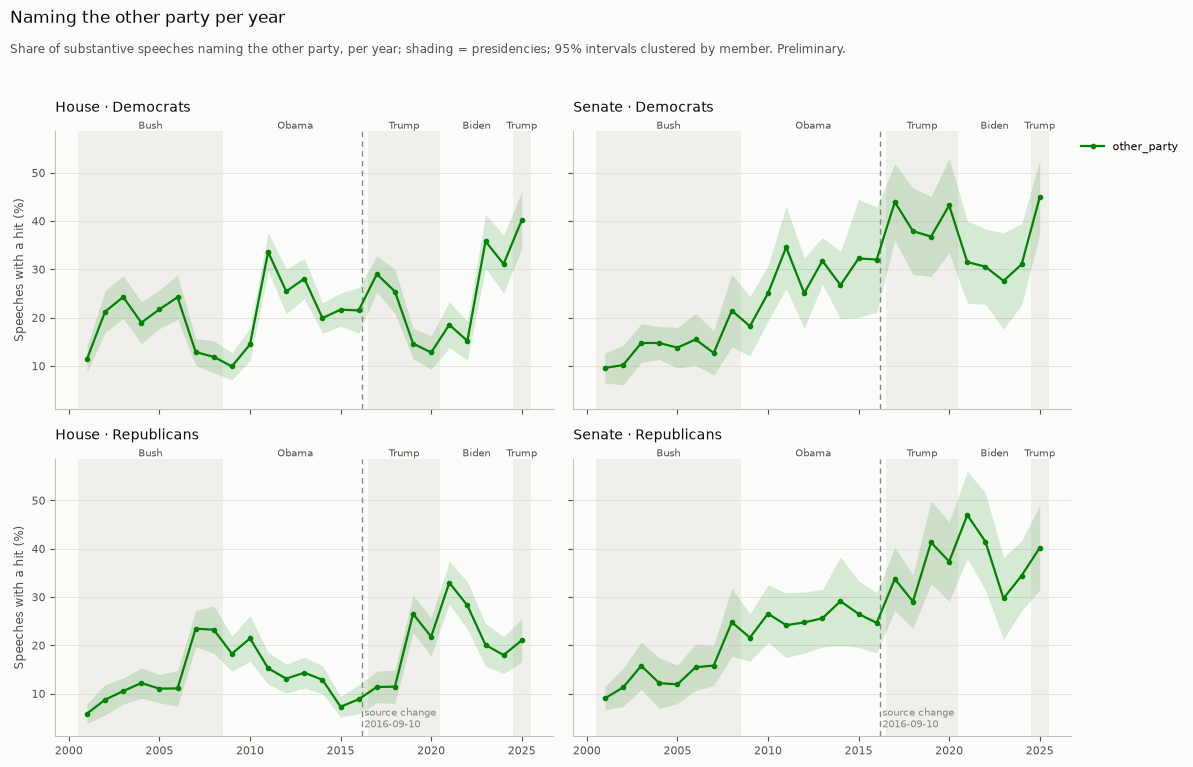

Tone with and without naming the other party (raw; 95% interval clustered by member):


mean_ci                               n      
names_other                          0                        1      0     1
chamber party                                                               
H       D      +0.304 [+0.291, +0.318]  +0.647 [+0.631, +0.663]  15423  4506
        R      +0.313 [+0.296, +0.329]  +0.595 [+0.573, +0.618]  15287  3026
S       D      +0.290 [+0.266, +0.313]  +0.629 [+0.593, +0.665]  12086  4706
        R      +0.306 [+0.279, +0.333]  +0.616 [+0.575, +0.656]  11832  4255

Difference within party x chamber x Congress:


,chamber,party,coef_ci,p,n,n_members
0,H,D,"+0.320 [+0.307, +0.332]",0.000e+00,19929,580
1,H,R,"+0.258 [+0.238, +0.277]",1.144e-143,18313,695
2,S,D,"+0.301 [+0.275, +0.327]",2.747e-113,16792,123
3,S,R,"+0.274 [+0.238, +0.310]",8.580e-50,16087,132


In [31]:
naming = keyword_shares(df.assign(year=YEAR), hits, ["other_party"], by=("year", "chamber", "party"))
fig = plot_yearly_keyword_lines(
    naming, ["other_party"],
    "Naming the other party per year",
    subtitle="Share of substantive speeches naming the other party, per year; shading = presidencies; 95% intervals clustered by member. Preliminary.",
    incomplete=INCOMPLETE_YEAR,
)
save_figure(fig, "deepdive_names_other_party")
plt.show()
naming_raw, naming_within = naming_tone(df, hits)
print("Tone with and without naming the other party (raw; 95% interval clustered by member):")
display(naming_raw.assign(mean_ci=with_ci(naming_raw, digits=3)).pivot(
    index=["chamber", "party"], columns="names_other", values=["mean_ci", "n"]))
print("Difference within party x chamber x Congress:")
naming_within.assign(coef_ci=with_ci(naming_within, "coef", 3))[["chamber", "party", "coef_ci", "p", "n", "n_members"]]

In [32]:
naming_corpus = keyword_shares(corpus.assign(year=CORPUS_YEAR), corpus_flags, ["other_party"],
                               by=("year", "chamber", "party"))
tables |= {"names_other_party": naming, "names_other_party_tone": naming_raw,
           "names_other_party_tone_within": naming_within, "names_other_party_corpus": naming_corpus}

**Reading it (3).**

- **Naming the other party grew most in the Senate:** from 9–10% of speeches in 2001 to
  40–45% in 2025 (Democrats 9.6% → 44.9%, Republicans 9.0% → 40.2%).
- **In the House it follows the majority:** Democrats name Republicans more in years they
  are the House minority (21% in 2002, 29% in 2017, 31–40% in 2024–2025) than when they hold
  it (10–13% in 2009 and 2020); Republicans likewise (23% in 2008 and 33% in 2021 in the
  minority; 6–11% in 2001 and 2016–2017 in the majority). Seen in the table, not tested.
- **Speeches that name the other party are harsher:** within party × chamber × Congress,
  tone +0.26 [+0.24, +0.28] (House Republicans) to +0.32 [+0.31, +0.33] (House Democrats);
  raw about 0.30 without and 0.60–0.65 with.
- **Whole corpus:** the same course at somewhat lower levels.

# Part IV — Discussion

## 11. Does polarization block progress?

**Question.** Does Congress pass fewer laws in the Congresses where the party gap is wider?

**Why.** It is the claim behind the thesis's motivation that polarization blocks progress,
put as plainly as the data allow.

**How.** Public laws enacted per Congress (congress.gov, `data/raw/external`) beside the
party gap (R − D, substantive speech, per chamber, as notebook 07). Pearson r over the
complete Congresses with a Fisher-z 95% interval, per chamber; and the r of the two series
after a linear trend is taken out of each, because both run over time. The 119th is
incomplete, shown hatched and left out of the correlation. **Descriptive only:** 12 data
points, no causal claim; the counts include ceremonial laws (post office namings and the
like), which Pew separates and these data do not.

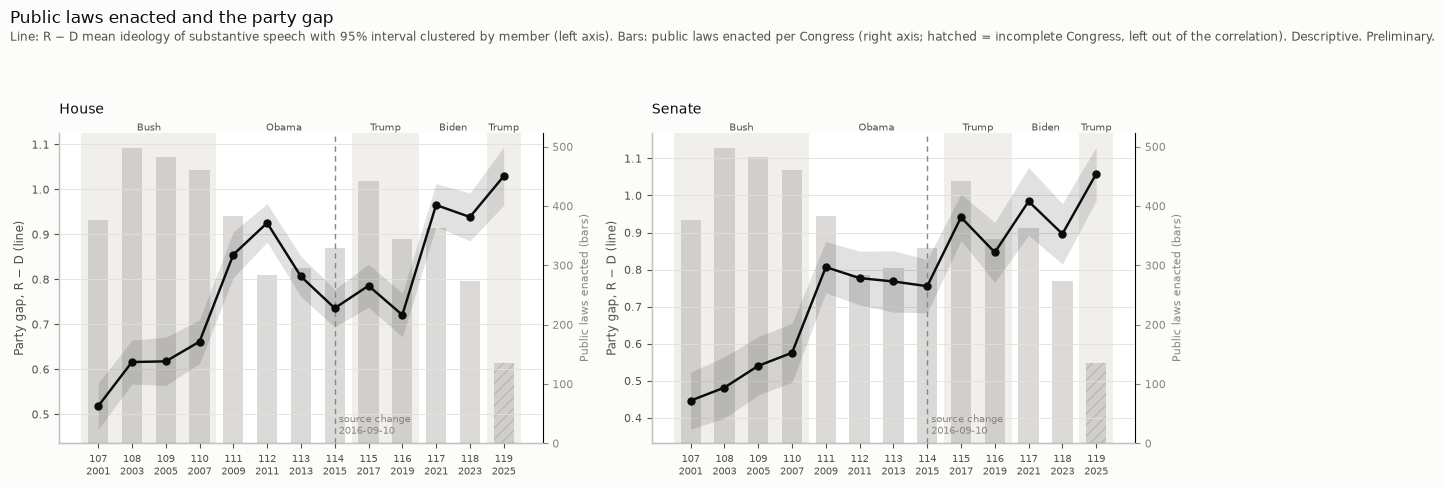

,chamber,kind,r_ci,n_congresses,congresses
0,H,raw,"-0.63 [-0.88, -0.08]",12,107-118
1,H,detrended,"-0.35 [-0.79, +0.31]",12,107-118
2,S,raw,"-0.53 [-0.85, +0.06]",12,107-118
3,S,detrended,"+0.01 [-0.59, +0.61]",12,107-118


In [33]:
gaps = party_gap(cell_means(df))
laws = load_public_laws()
laws_gap = gaps.merge(laws, on="congress_number", how="left", validate="m:1")
assert laws_gap["public_laws"].notna().all(), "a Congress has no law count"
correlation = laws_gap_correlation(laws_gap)
fig = plot_laws_and_gap(
    laws_gap,
    "Public laws enacted and the party gap",
    subtitle="Line: R − D mean ideology of substantive speech with 95% interval clustered by member (left axis). Bars: public laws enacted per Congress (right axis; hatched = incomplete Congress, left out of the correlation). Descriptive. Preliminary.",
)
save_figure(fig, "deepdive_laws_gap")
plt.show()
correlation.assign(r_ci=with_ci(correlation, "r", 2))[["chamber", "kind", "r_ci", "n_congresses", "congresses"]]

In [34]:
tables |= {"laws_gap": laws_gap, "laws_gap_correlation": correlation}

**Reading it (11).** Descriptive; 12 complete Congresses; law counts include ceremonial laws.

- **House:** r = −0.63 [−0.88, −0.08] over the 107th–118th; after a linear trend is taken
  out of both series, −0.35 [−0.79, +0.31].
- **Senate:** r = −0.53 [−0.85, +0.06]; detrended +0.01 [−0.59, +0.61].
- Once the trend is removed, neither chamber shows a clear association.

## Saving the tables

In [35]:
print("Bootstrap and keyword run times (minutes):", {k: round(v / 60, 1) for k, v in timings.items()})
for name, table in tables.items():
    path = METRICS_DIR / f"deepdive_{name}_{RUN}.csv"
    table.to_csv(path, index=False)
    print(path.relative_to(ROOT))

Bootstrap and keyword run times (minutes): {'dissent bootstrap': 2.8, 'corpus keyword pass': 10.2, 'switch decomposition bootstrap': 5.9, 'common ground bootstrap (all)': 2.1, 'common ground bootstrap (blocks)': 5.0}
results/metrics/deepdive_event_windows_20261018T122536Z.csv
results/metrics/deepdive_event_cell_sizes_20261018T122536Z.csv
results/metrics/deepdive_event_effects_20261018T122536Z.csv
results/metrics/deepdive_event_quarterly_20261018T122536Z.csv
results/metrics/deepdive_cohort_extremity_20261018T122536Z.csv
results/metrics/deepdive_cohort_switchers_left_out_20261018T122536Z.csv
results/metrics/deepdive_dissent_20261018T122536Z.csv
results/metrics/deepdive_moderate_exit_20261018T122536Z.csv
results/metrics/deepdive_moderate_exit_lpm_20261018T122536Z.csv
results/metrics/deepdive_last_congress_20261018T122536Z.csv
results/metrics/deepdive_last_congress_identifying_20261018T122536Z.csv
results/metrics/deepdive_keyword_precision_20261018T122536Z.csv
results/metrics/deepdive_keyw